# RAVE-VL v4 · Portion 8 — offline policy search on the existing passes (CPU only, no A100 time)

Portions 3–7 showed that **one crop for 30% of questions** does not beat spending the same tokens on uniform resolution.
Every benchmark already has dense passes at 128 / 256 / 512 / 1,024 / native tokens (plus the crop passes), so every
**gated cascade** — answer at a low budget, then re-answer the risky questions at a higher budget (or with a crop) — can
be scored exactly, without any new GPU time.

**Design (venue standard: discovery → freeze → confirmation).**
1. **Pre-declared analysis plan**, hashed before anything is computed (`logs/p8_analysis_plan.json`); a re-run with a
   changed plan stops. These analyses are *exploratory* (Portions 3–7 have been seen); only Portion 9 is confirmatory.
2. **Policy space**: Stage-1 budget {128, 256, 512} × escalation target {512, 1,024, native, global + crop, up-scaled
   global, 4 quadrants} × gate {confidence (LookWise-style), entropy, margin, answer-only LR, resolution-aware LR,
   **uplift** (predicts whether escalation *fixes* the answer)} × merge {replace, log-linear pooling}; plus a 3-stage
   cascade 128 → 512 → native.
3. **Baseline = the uniform-resolution upper hull**: the best accuracy any random mix of uniform budgets reaches at the
   same average cost (stricter than joining the points), at equal **visual tokens** and at equal **measured GPU time**;
   CIs from a paired bootstrap over **image clusters** (questions that share a photograph, and HR-Bench's four option
   rotations, are resampled together), with the hull recomputed in every resample.
4. **Operating points** fixed in advance: 25% of native visual tokens (the quarter-resolution start of VisionThink) and 50%.
5. **Leave-one-benchmark-out**: the policy family is chosen on the other benchmarks, learned gates are fitted on them
   too, and the held-out benchmark only supplies its answers for scoring.
6. **Frozen policy** (`logs/p8_frozen_policy.json`, SHA-256) for Portion 9 to confirm on a new benchmark and a new backbone.

Outputs: `rave_work/paper_p8/` (CSV + LaTeX) and `rave_work/figures/fig_p8_*`.

In [1]:
%pip install -q pandas pyarrow scikit-learn scipy matplotlib psutil tqdm nvidia-ml-py

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 2.1 MB/s eta 0:00:00


In [2]:
import os, sys, json, math, re, time, random, string, hashlib, zlib, warnings, shutil, tarfile
from pathlib import Path
import multiprocessing as mp
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

def usable_cpus():
    """CPUs this process may really use (affinity + cgroup quota). os.cpu_count() inside a container often
    reports every host core, which oversubscribes threads and makes CPU work crawl."""
    n = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else (os.cpu_count() or 1)
    try:                                                            # cgroup v2
        q, p = open("/sys/fs/cgroup/cpu.max").read().split()[:2]
        if q != "max":
            n = min(n, max(1, int(q) // int(p)))
    except Exception:
        try:                                                        # cgroup v1
            q = int(open("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read())
            p = int(open("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read())
            if q > 0:
                n = min(n, max(1, q // p))
        except Exception:
            pass
    return max(1, n)

N_CPU = int(os.environ.get("RAVE_CPUS", usable_cpus()))
for _v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ.setdefault(_v, str(N_CPU))
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
# fewer "out of memory" errors from fragmentation when batch shapes vary (must be set before torch is imported)
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

# ── Storage: fast local working copy + permanent copy in Google Drive ("Koushik 2") ─────────────
# Colab's /content disk is wiped whenever the runtime is recycled (new GPU, disconnect, restart of the VM), so
# every portion works on local disk for speed and mirrors everything to Drive after every phase. The next
# portion restores from Drive automatically, on any runtime.
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
DRIVE_FOLDER = os.environ.get("RAVE_DRIVE_FOLDER", "Koushik 2")
if os.environ.get("RAVE_DRIVE_ROOT"):                 # any folder can stand in for Drive (tests, other machines)
    DRIVE_ROOT = Path(os.environ["RAVE_DRIVE_ROOT"]) / DRIVE_FOLDER
elif IN_COLAB:
    DRIVE_HELP = """Google Drive did not mount ({err}).
How to fix it (most common cause first):
  1. Run this cell again. In the Google sign-in window pick the SAME account that runs this notebook and tick EVERY
     permission box (in particular "See, edit, create and delete all of your Google Drive files"), then Continue.
  2. Or: folder icon in Colab's left sidebar -> "Mount Drive" (mounts without the pop-up), then run this cell again.
  3. Still failing: Runtime -> Disconnect and delete runtime, allow pop-ups for colab.research.google.com, start again.
Nothing has been computed yet, so nothing is lost."""

    def _mount_drive():
        if os.path.isdir("/content/drive/MyDrive"):
            return
        from google.colab import drive
        err = None
        for kw in ({}, {"force_remount": True}):          # second try = a fresh sign-in window
            try:
                drive.mount("/content/drive", timeout_ms=300_000, **kw)
            except Exception as e:                       # e.g. "credential propagation was unsuccessful"
                err = e
                print(f"  Drive mount attempt failed: {type(e).__name__}: {e}")
            if os.path.isdir("/content/drive/MyDrive"):
                return
        raise RuntimeError(DRIVE_HELP.format(err=f"{type(err).__name__}: {err}" if err else "MyDrive not visible"))

    _mount_drive()
    DRIVE_ROOT = Path("/content/drive/MyDrive") / DRIVE_FOLDER
else:
    DRIVE_ROOT = None
if DRIVE_ROOT is not None:
    DRIVE_ROOT.mkdir(parents=True, exist_ok=True)
DRIVE_WORK = DRIVE_ROOT / "rave_work" if DRIVE_ROOT is not None else None
WORK = Path(os.environ.get("RAVE_WORK", "/content/rave_work" if IN_COLAB else "./rave_work")).resolve()
DIRS = {k: WORK / k for k in ["raw", "global", "crops", "meta", "logs", "preds"]}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
HEAVY_DIRS = {"raw", "global", "crops"}               # thousands of images -> stored on Drive as one tar per dataset

def _walk_small(root):
    for dirpath, dirnames, filenames in os.walk(root):
        dirnames[:] = [d for d in dirnames if d not in HEAVY_DIRS]
        for f in filenames:
            if f == "images.tar" or f.endswith(".partial"):
                continue
            yield Path(dirpath) / f

import threading
_SYNC_LOCK = threading.Lock()
_SYNCED = {}                                           # local path -> (size, mtime_ns) already on Drive

def _key(st):
    return (st.st_size, st.st_mtime_ns)

def sync_to_drive(quiet=True):
    """Copy every new/changed small file (tables, predictions, logs, figures) from WORK to Drive.
    Files already copied are remembered, so Drive (slow to query) is only touched for real changes; each copy goes
    to '<name>.partial' first and is then renamed, so a runtime that dies mid-copy never leaves a broken file."""
    if DRIVE_WORK is None:
        return 0
    n = 0
    with _SYNC_LOCK:
        for p in _walk_small(WORK):
            try:
                st = p.stat()
                if _SYNCED.get(p) == _key(st):
                    continue
                q = DRIVE_WORK / p.relative_to(WORK)
                try:
                    qs = q.stat()
                    if qs.st_size == st.st_size and qs.st_mtime >= st.st_mtime - 2:
                        _SYNCED[p] = _key(st)
                        continue
                except FileNotFoundError:
                    pass
                q.parent.mkdir(parents=True, exist_ok=True)
                tmp = q.with_name(q.name + ".partial")
                shutil.copyfile(p, tmp)
                try:
                    shutil.copystat(p, tmp)                # keeps mtimes when the Drive mount allows it
                except OSError:
                    pass
                os.replace(tmp, q)
                _SYNCED[p] = _key(st)
                n += 1
            except OSError as e:                           # a Drive hiccup must never kill a GPU run
                print(f"  (Drive sync skipped {p.name}: {e})")
    if not quiet:
        print(f"Drive sync: {n} file(s) -> {DRIVE_WORK}")
    return n

def sync_in_background():
    """Non-blocking sync for use inside GPU loops (skipped if a sync is already running)."""
    if DRIVE_WORK is None or _SYNC_LOCK.locked():
        return
    threading.Thread(target=lambda: sync_to_drive(), daemon=True).start()

def archive_images_to_drive(sub="", dirs=None):
    """Pack raw/, global/, crops/ of WORK/sub into one tar on Drive (thousands of small files are slow on Drive).
    dirs: which of them to keep (e.g. {"global", "crops"} when the originals can be downloaded again)."""
    if DRIVE_WORK is None:
        return
    base, dst = WORK / sub, DRIVE_WORK / sub / "images.tar"
    dst.parent.mkdir(parents=True, exist_ok=True)
    part = dst.with_name("images.tar.partial")
    with tarfile.open(part, "w") as tf:
        for d in sorted(dirs or HEAVY_DIRS):
            if (base / d).exists():
                tf.add(base / d, arcname=d)
    os.replace(part, dst)
    print(f"images archived -> {dst} ({dst.stat().st_size / 1e9:.2f} GB)")

def restore_from_drive(sub="", images=True):
    """Bring WORK/sub back from Drive on a fresh runtime: small files copied, images extracted from the tar."""
    if DRIVE_WORK is None:
        print("no Drive folder configured: using local files only"); return
    src = DRIVE_WORK / sub
    if not src.exists():
        print(f"nothing on Drive yet at {src}"); return
    n = 0
    for p in _walk_small(src):
        q = WORK / p.relative_to(DRIVE_WORK)
        if p.name == "time_ledger.jsonl" and q.exists():   # merge: Drive history + rows this runtime already wrote
            drive_text = p.read_text()
            seen = set(drive_text.splitlines())
            local_new = [l for l in q.read_text().splitlines() if l and l not in seen]
            q.write_text(drive_text + ("" if drive_text.endswith("\n") or not drive_text else "\n")
                         + "".join(l + "\n" for l in local_new))
            n += 1
            continue
        if not q.exists() or q.stat().st_size != p.stat().st_size:
            q.parent.mkdir(parents=True, exist_ok=True); shutil.copy2(p, q); n += 1
        _SYNCED[q] = _key(q.stat())                    # identical to Drive: the next sync skips it
    tar, gdir = src / "images.tar", WORK / sub / "global"
    extracted = False
    if images and tar.exists() and not (gdir.exists() and any(gdir.iterdir())):
        with tarfile.open(tar) as tf:
            try:
                tf.extractall(WORK / sub, filter="data")
            except TypeError:                          # Python < 3.12
                tf.extractall(WORK / sub)
        extracted = True
    print(f"restored {n} file(s) from {src}" + (" + images" if extracted else ""))

def save_notebook_copy(name):
    """Colab only: write this notebook WITH its outputs into Drive/<folder>/notebooks/."""
    if not IN_COLAB or DRIVE_ROOT is None:
        print("not running in Colab: save the notebook yourself"); return
    try:
        from google.colab import _message
        nb = _message.blocking_request("get_ipynb", timeout_sec=120)["ipynb"]
        out = DRIVE_ROOT / "notebooks" / f"{name}_executed_{time.strftime('%Y%m%d_%H%M')}.ipynb"
        out.parent.mkdir(parents=True, exist_ok=True)
        out.write_text(json.dumps(nb))
        print("notebook with outputs ->", out)
    except Exception as e:
        print(f"could not save the notebook automatically ({e}); use File > Save a copy in Drive")

SEED = 20261017
random.seed(SEED)
SMOKE_N = int(os.environ.get("RAVE_SMOKE_N", "0"))       # 0 = full run (1,730 questions); >0 = quick test

DATASET, CONFIG = "MMMU/MMMU_Pro", "standard (10 options)"
MODEL_ID = os.environ.get("RAVE_MODEL_ID", "Qwen/Qwen3-VL-8B-Instruct")

# Qwen3-VL geometry: 16-px patches + 2x2 spatial merge -> 1 LLM visual token per 32x32 px.
FACTOR = 32
PX_PER_TOKEN = FACTOR * FACTOR
MIN_IMG_TOKENS = 64                      # Qwen3-VL default floor (shortest_edge = 65,536 px)
GLOBAL_BUDGETS = [128, 256, 512, 1024]   # Stage-1 visual tokens per QUESTION -> uniform-resolution frontier
NATIVE_CAP = 4096                        # "native" reference: only downscaled above 4,096 tokens per question
BASES = [str(b) for b in GLOBAL_BUDGETS] + ["native"]
MAIN_BASE = "256"                        # pre-registered Stage-1 budget (P1.3 prints the label-free reason)
PROTOCOL_BASE = "1024"                   # v1 protocol budget, kept as the secondary operating point
CROP_TOKENS_MIN, CROP_TOKENS_MAX = 256, 512   # one escalation crop; small regions are up-sampled (= the zoom)
LETTERS = string.ascii_uppercase         # MMMU-Pro standard(10) has 2-12 options (one question has 12)
PH = re.compile(r"<image (\d+)>")
INSTR = "Answer with the option's letter from the given choices directly."
PROMPT_VERSION = "v2-prefix-compatible"
print(f"WORK={WORK} | Drive={DRIVE_WORK} | usable CPUs={N_CPU} (os.cpu_count()={os.cpu_count()}) | "
      f"model={MODEL_ID} | SMOKE_N={SMOKE_N or 'full run'}")

NOTEBOOK = "P8"
DEVICE, ON_GPU = "cpu", False
MAX_OPT = 12
COST_FILE = DIRS["logs"] / "variant_costs.json"
P8 = WORK / "paper_p8"
P8.mkdir(parents=True, exist_ok=True)
N_BOOT8 = int(os.environ.get("RAVE_N_BOOT", "1000"))

def _sha256_file(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

Mounted at /content/drive
WORK=/content/rave_work | Drive=/content/drive/MyDrive/Koushik 2/rave_work | usable CPUs=2 (os.cpu_count()=2) | model=Qwen/Qwen3-VL-8B-Instruct | SMOKE_N=full run


In [3]:
# ── CPU + GPU time ledger: EVERY executed cell and every named phase gets one row ─────────────
#  cpu_s        CPU-seconds of this kernel + its worker processes (Pool / DataLoader workers)
#  cores_used   cpu_s / wall_s   (how many cores the step really kept busy)
#  gpu_busy_s   phase rows: sum of CUDA-event-timed forward passes (exact)
#               cell rows : integral of NVML GPU utilisation, sampled every 0.25 s (approximate)
#               0.00 + "none" when no GPU is used (e.g. the whole of Portion 1)
#  gpu_energy_J NVML board-energy counter difference (supported on A100)
import time, json, resource, threading, datetime as dt
import psutil

LEDGER = DIRS["logs"] / "time_ledger.jsonl"
WINDOW_FILE = DIRS["logs"] / "a100_window.json"
WINDOW_H = 7.0

def _nvml():
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            import pynvml                        # provided by nvidia-ml-py
        pynvml.nvmlInit()
        cvd = os.environ.get("CUDA_VISIBLE_DEVICES", "0").split(",")[0].strip()
        h = pynvml.nvmlDeviceGetHandleByIndex(int(cvd) if cvd.isdigit() else 0)
        name = pynvml.nvmlDeviceGetName(h)
        return pynvml, h, (name.decode() if isinstance(name, bytes) else name)
    except Exception:
        return None, None, None
NV, NVH, GPU_NAME = _nvml()

def _energy_mJ():
    if NVH is None:
        return None
    try:
        return NV.nvmlDeviceGetTotalEnergyConsumption(NVH)
    except Exception:
        return None

def _torch_cuda():
    t = sys.modules.get("torch")
    try:
        return t if (t is not None and t.cuda.is_available() and t.cuda.is_initialized()) else None
    except Exception:
        return None

def _reaped_child_cpu():
    r = resource.getrusage(resource.RUSAGE_CHILDREN)
    return r.ru_utime + r.ru_stime

def _alive_children():
    out = {}
    try:
        for c in psutil.Process().children(recursive=True):
            try:
                t = c.cpu_times(); out[c.pid] = t.user + t.system
            except psutil.Error:
                pass
    except psutil.Error:
        pass
    return out

GPU_NOTEBOOKS = {"P2", "P3", "P4", "P5", "P6", "P9"}     # P1, P7, P8 run on a CPU runtime, outside the A100 window

def _ledger_window_s():
    s = 0.0
    if LEDGER.exists():
        with open(LEDGER) as f:
            for line in f:
                try:
                    r = json.loads(line)
                except ValueError:
                    continue
                if r.get("kind") == "cell" and r.get("notebook") in GPU_NOTEBOOKS and r.get("counts_to_window", True):
                    s += float(r.get("wall_s") or 0)
    return s

def window_used_h():
    """A100 hours used = executed cell time of all GPU portions (P2-P4), summed across runtimes (the ledger lives
    on Drive). Weight downloads are excluded. Idle time between cells is not counted."""
    if globals().get("NOTEBOOK") not in GPU_NOTEBOOKS:
        return None
    s = _ledger_window_s()
    ct = globals().get("CELL_TIMER")
    if ct is not None and ct.m is not None and getattr(ct, "counts", True):
        s += time.perf_counter() - ct.m.t0
    return round(s / 3600, 3)

def window(tag=""):
    used = window_used_h()
    if used is None:
        print(f"⏱ A100 time {tag}: not counted in this portion"); return
    print(f"⏱ A100 time {tag}: {used:.2f} h used, {WINDOW_H - used:.2f} h left of {WINDOW_H:.0f} h (GPU-portion cells)")
    if used > WINDOW_H:
        print("  ⚠ 7-hour budget exceeded")

class _Sampler(threading.Thread):
    def __init__(self, period=0.25):
        super().__init__(daemon=True)
        self.period, self.cpu, self.gpu, self.mem, self.ram = period, [], [], [], []
        self._halt = threading.Event()
    def run(self):
        while not self._halt.wait(self.period):
            self.cpu.append(psutil.cpu_percent(None))
            self.ram.append(psutil.virtual_memory().used / 1e9)
            if NVH is not None:
                try:
                    self.gpu.append(NV.nvmlDeviceGetUtilizationRates(NVH).gpu)
                    self.mem.append(NV.nvmlDeviceGetMemoryInfo(NVH).used / 1e9)
                except Exception:
                    pass
    def stop(self):
        self._halt.set(); self.join(timeout=2)
        return self

class _Meter:
    """Start/stop meter shared by Phase (named steps) and the automatic per-cell timer."""
    def start(self):
        tc = _torch_cuda()
        if tc is not None:
            tc.cuda.synchronize(); tc.cuda.reset_peak_memory_stats()
        self.started = dt.datetime.now().isoformat(timespec="seconds")
        self.kids0 = _alive_children()
        self.t0, self.c0, self.k0, self.e0 = time.perf_counter(), time.process_time(), _reaped_child_cpu(), _energy_mJ()
        self.s = _Sampler(); self.s.start()
        return self
    def stop(self):
        tc = _torch_cuda()
        if tc is not None:
            tc.cuda.synchronize()
        wall = time.perf_counter() - self.t0
        cpu_self = time.process_time() - self.c0
        kids1 = _alive_children()
        reaped = _reaped_child_cpu() - self.k0 - sum(v for p, v in self.kids0.items() if p not in kids1)
        alive = sum(v - self.kids0.get(p, 0.0) for p, v in kids1.items())
        cpu_child = max(0.0, reaped) + max(0.0, alive)
        s = self.s.stop(); e1 = _energy_mJ()
        mean = lambda xs: round(sum(xs) / len(xs), 1) if xs else None
        return dict(started=self.started, wall_s=round(wall, 3), cpu_s=round(cpu_self + cpu_child, 3),
                    cpu_self_s=round(cpu_self, 3), cpu_child_s=round(cpu_child, 3),
                    cores_used=round((cpu_self + cpu_child) / max(wall, 1e-9), 2), sys_cpu_util_pct=mean(s.cpu),
                    gpu_present=(NVH is not None) or (tc is not None), gpu_name=GPU_NAME,
                    gpu_util_pct=mean(s.gpu),
                    gpu_active_s=round(sum(s.gpu) / 100 * s.period, 3) if s.gpu else 0.0,
                    gpu_energy_J=round((e1 - self.e0) / 1000, 1) if (e1 is not None and self.e0 is not None) else None,
                    gpu_mem_used_gb_max=round(max(s.mem), 2) if s.mem else None,
                    gpu_peak_alloc_gb=round(tc.cuda.max_memory_allocated() / 1e9, 2) if tc is not None else None,
                    ram_used_gb_max=round(max(s.ram), 1) if s.ram else round(psutil.virtual_memory().used / 1e9, 1),
                    window_h_used=window_used_h())

def _write(row):
    with open(LEDGER, "a") as f:
        f.write(json.dumps(row, default=str) + "\n")

def _fmt(r):
    if r["gpu_busy_src"] == "none":
        g = "GPU 0.00 s (no GPU used)"
    else:
        g = f"GPU busy {r['gpu_busy_s']:.2f} s [{r['gpu_busy_src']}]"
        if r.get("gpu_util_pct") is not None:
            g += f", util {r['gpu_util_pct']}%"
        if r.get("gpu_energy_J"):
            g += f", {r['gpu_energy_J'] / 1000:.2f} kJ"
        if r.get("gpu_peak_alloc_gb"):
            g += f", peak {r['gpu_peak_alloc_gb']} GB"
    w = f" | A100 time {r['window_h_used']:.2f}/{WINDOW_H:.0f} h" if r.get("window_h_used") is not None else ""
    ram = f" | RAM peak {r['ram_used_gb_max']:.0f} GB" if r.get("ram_used_gb_max") is not None else ""
    return (f"⏱ {r['name']} | wall {r['wall_s']:.2f} s | CPU {r['cpu_s']:.2f} s ({r['cores_used']} cores, "
            f"sys {r['sys_cpu_util_pct']}%) | {g}{ram}{w}" + ("" if r["ok"] else "  ** FAILED **"))

class _GpuTimer:
    """Exact device time of one forward pass (CUDA events; perf_counter if the model runs on CPU)."""
    def __init__(self, phase=None):
        self.phase, self.s = phase, 0.0
    def __enter__(self):
        tc = _torch_cuda(); self.cuda = tc is not None
        if self.cuda:
            self.e0, self.e1 = tc.cuda.Event(enable_timing=True), tc.cuda.Event(enable_timing=True); self.e0.record()
        else:
            self.t0 = time.perf_counter()
        return self
    def __exit__(self, *exc):
        if self.cuda:
            self.e1.record(); self.e1.synchronize(); self.s = self.e0.elapsed_time(self.e1) / 1000
        else:
            self.s = time.perf_counter() - self.t0
        if self.phase is not None:
            self.phase.gpu_busy_s += self.s; self.phase.n_dev_calls += 1
            self.phase.dev_src = "cuda_events" if self.cuda else "cpu_device_forward"
        return False

class Phase:
    """with Phase("P2.B B0", budget_min=10) as ph: ...  -> one 'phase' row (wall, CPU, GPU, energy).
    Wrap each forward pass in `with ph.gpu():` to add its exact CUDA-event time to gpu_busy_s."""
    def __init__(self, name, budget_min=None):
        self.name, self.budget_min, self.extra = name, budget_min, {}
        self.gpu_busy_s, self.n_dev_calls, self.dev_src, self.row = 0.0, 0, None, None
    def gpu(self):
        return _GpuTimer(self)
    def __enter__(self):
        self.m = _Meter().start(); return self
    def __exit__(self, et, ev, tb):
        r = self.m.stop()
        if self.n_dev_calls:
            busy, src = self.gpu_busy_s, self.dev_src
        elif r["gpu_active_s"] > 0:
            busy, src = r["gpu_active_s"], "nvml_util"
        else:
            busy, src = 0.0, ("none" if not r["gpu_present"] or not r["gpu_util_pct"] else "nvml_util")
        self.row = dict(kind="phase", notebook=NOTEBOOK, name=self.name, ok=et is None, **r,
                        gpu_busy_s=round(busy, 3), gpu_busy_src=src, n_forward=self.n_dev_calls,
                        budget_min=self.budget_min, **self.extra)
        _write(self.row); print(_fmt(self.row))
        if self.budget_min and r["wall_s"] > 60 * self.budget_min:
            print(f"  ⚠ over budget: {r['wall_s'] / 60:.1f} min > {self.budget_min} min")
        try:
            sync_in_background()                       # every finished phase goes to Drive (without blocking)
        except Exception as e:
            print(f"  (Drive sync failed: {e})")
        return False

class _CellTimer:
    def __init__(self):
        self.m, self.n, self.counts, self.last_sync = None, 0, True, time.time()
    def pre(self, info=None):
        raw = (getattr(info, "raw_cell", "") or "").strip()
        self.label = raw.splitlines()[0][:60] if raw else ""
        self.counts = "[no-window]" not in self.label           # e.g. weight downloads are not A100 time
        self.m = _Meter().start()
    def post(self, result=None):
        if self.m is None:
            return
        r = self.m.stop()
        self.m = None
        self.n += 1
        src = "nvml_util" if r["gpu_util_pct"] is not None else "none"
        row = dict(kind="cell", notebook=NOTEBOOK, name=f"cell {self.n}: {self.label}",
                   ok=bool(getattr(result, "success", True)), **r, counts_to_window=self.counts,
                   gpu_busy_s=r["gpu_active_s"] if src != "none" else 0.0, gpu_busy_src=src)
        _write(row); print(_fmt(row))
        if time.time() - self.last_sync > 20:
            try:
                sync_in_background(); self.last_sync = time.time()
            except Exception as e:
                print(f"  (Drive sync failed: {e})")

def _register_cell_timer():
    try:
        ip = get_ipython()                       # noqa: F821  (exists inside Jupyter)
    except NameError:
        return None
    old = getattr(ip, "_rave_cell_timer", None)
    if old is not None:
        for ev, fn in (("pre_run_cell", old.pre), ("post_run_cell", old.post)):
            try:
                ip.events.unregister(ev, fn)
            except ValueError:
                pass
    t = _CellTimer()
    ip.events.register("pre_run_cell", t.pre)
    ip.events.register("post_run_cell", t.post)
    ip._rave_cell_timer = t
    t.label = "(timer setup cell)"
    t.m = _Meter().start()                       # so this very cell is logged too
    return t

def time_report(notebook=None, save=True):
    """Totals (from per-cell rows = everything executed) + per-phase CPU/GPU table."""
    import pandas as pd
    if not LEDGER.exists():
        print("ledger empty"); return None
    df = pd.read_json(LEDGER, lines=True)
    if notebook:
        df = df[df.notebook == notebook]
    ce, ph = df[df.kind == "cell"], df[df.kind == "phase"].copy()
    en = ce["gpu_energy_J"].fillna(0).sum() if "gpu_energy_J" in ce else 0.0
    gpu_ph = ph[ph.gpu_busy_src.isin(["cuda_events", "nvml_util"])].gpu_busy_s.sum() if len(ph) else 0.0
    cpu_dev = ph[ph.gpu_busy_src == "cpu_device_forward"].gpu_busy_s.sum() if len(ph) else 0.0
    print(f"[{notebook or 'all notebooks'}] {len(ce)} cells | wall {ce.wall_s.sum() / 60:.1f} min | "
          f"CPU {ce.cpu_s.sum() / 60:.1f} CPU-min ({ce.cpu_s.sum() / max(ce.wall_s.sum(), 1e-9):.1f} cores avg) | "
          f"GPU busy {gpu_ph / 60:.2f} min (phases) / {ce.gpu_busy_s.sum() / 60:.2f} min (cells, NVML) | "
          f"GPU energy {en / 1000:.1f} kJ" + (f" | model forward on CPU (no GPU) {cpu_dev / 60:.2f} min" if cpu_dev else "") +
          (f" | A100 time used (GPU portions) {window_used_h():.2f} h of {WINDOW_H:.0f}" if window_used_h() is not None else ""))
    cols = ["name", "ok", "wall_s", "cpu_s", "cores_used", "sys_cpu_util_pct", "gpu_busy_s", "gpu_busy_src",
            "gpu_util_pct", "gpu_energy_J", "gpu_peak_alloc_gb", "ram_used_gb_max", "n_forward", "budget_min",
            "window_h_used"]
    ph = ph[[c for c in cols if c in ph]].reset_index(drop=True)
    if save:
        ph.to_csv(DIRS["logs"] / f"time_phases_{notebook or 'all'}.csv", index=False)
    return ph

CELL_TIMER = _register_cell_timer()
print("per-cell CPU/GPU timer:", "ON" if CELL_TIMER else "off (not in Jupyter)",
      "| GPU visible:", GPU_NAME or "none", "| ledger:", LEDGER)

per-cell CPU/GPU timer: ON | GPU visible: none | ledger: /content/rave_work/logs/time_ledger.jsonl
⏱ cell 1: (timer setup cell) | wall 0.00 s | CPU 0.00 s (1.0 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 1 GB


In [4]:
# [no-window] restore every portion's small files (tables, predictions, logs) from Drive — images are not needed
restore_from_drive(images=False)

restored 845 file(s) from /content/drive/MyDrive/Koushik 2/rave_work
⏱ cell 2: # [no-window] restore every portion's small files (tables, p | wall 298.27 s | CPU 1.55 s (0.01 cores, sys 25.3%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB


In [5]:
# ── Statistics used for every claim (paired, per-question) ────────────────────────────────────
import numpy as np

def boot_ci(x, n=5000, seed=SEED):
    x = np.asarray(x, float); rng = np.random.default_rng(seed)
    m = np.array([x[rng.integers(0, len(x), len(x))].mean() for _ in range(n)])
    return float(x.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

def paired_boot(a, b, n=5000, seed=SEED):
    """mean(a - b), 95% CI, one-sided bootstrap p-value for H0: mean(a - b) <= 0."""
    d = np.asarray(a, float) - np.asarray(b, float); rng = np.random.default_rng(seed)
    m = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(n)])
    return float(d.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5)), float((m <= 0).mean())

def mcnemar_exact(a_correct, b_correct):
    from scipy.stats import binomtest
    a, b = np.asarray(a_correct, bool), np.asarray(b_correct, bool)
    n10, n01 = int((a & ~b).sum()), int((~a & b).sum())
    p = binomtest(n10, n10 + n01, 0.5).pvalue if n10 + n01 else 1.0
    return n10, n01, float(p)

def holm(pvals, alpha=0.05):
    items = sorted(pvals.items(), key=lambda kv: kv[1]); m = len(items); out, stop = {}, False
    for i, (k, p) in enumerate(items):
        stop = stop or p > alpha / (m - i)
        out[k] = dict(p=p, p_holm=min(1.0, max(p * (m - j) for j, (_, p) in enumerate(items[:i + 1]))), reject=not stop)
    return out

def ece(y, p, bins=15):
    y, p = np.asarray(y, float), np.asarray(p, float)
    idx = np.clip(np.digitize(p, np.linspace(0, 1, bins + 1)) - 1, 0, bins - 1)
    return float(sum(abs(y[idx == b].mean() - p[idx == b].mean()) * (idx == b).mean()
                     for b in range(bins) if (idx == b).any()))

def aurc(err, risk):
    """Area under the risk-coverage curve: accept most-confident first; lower is better."""
    o = np.argsort(risk, kind="stable"); e = np.asarray(err, float)[o]
    return float((np.cumsum(e) / np.arange(1, len(e) + 1)).mean())

def boot_ci_fast(x, n=2000, seed=SEED):
    """Bootstrap CI for a mean using a multinomial weight matrix (fast, memory-light)."""
    x = np.asarray(x, float)
    if len(x) < 2:
        return float(x.mean()) if len(x) else float("nan"), float("nan"), float("nan")
    rng = np.random.default_rng(seed)
    w = rng.multinomial(len(x), np.full(len(x), 1 / len(x)), size=n) / len(x)
    m = w @ x
    return float(x.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

_TEX_UNI = {"Δ": r"$\Delta$", "−": r"$-$", "✓": r"$\surd$", "✗": r"$\times$", "†": r"$^\dagger$", "≈": r"$\approx$",
            "≤": r"$\le$", "≥": r"$\ge$", "×": r"$\times$", "→": r"$\rightarrow$", "∞": r"$\infty$", "·": r"$\cdot$",
            "–": "--", "—": "---", "…": r"\ldots{}", "₂": r"$_2$", "ε": r"$\varepsilon$", "ρ": r"$\rho$", "δ": r"$\delta$"}

def tex(s):
    """Escape for LaTeX and replace every non-ASCII symbol so the tables compile with plain pdflatex (IEEEtran)."""
    out = str(s).replace("\\", "/").replace("_", r"\_").replace("%", r"\%").replace("&", r"\&").replace("#", r"\#")
    for k, v in _TEX_UNI.items():
        out = out.replace(k, v)
    return out

def to_booktabs(df, path, caption, label, align=None, wide=None):
    """Write a LaTeX booktabs table (no jinja2 dependency). Wide tables (> 7 columns) become a two-column table*
    scaled to the text width (needs graphicx, loaded by the IEEE templates)."""
    cols = list(df.columns)
    align = align or ("l" + "r" * (len(cols) - 1))
    wide = len(cols) > 7 if wide is None else wide
    env = "table*" if wide else "table"
    lines = [rf"\begin{{{env}}}[t]", r"\centering", r"\small", rf"\caption{{{tex(caption)}}}", rf"\label{{{label}}}"]
    if wide:
        lines.append(r"\resizebox{\textwidth}{!}{%")
    lines += [rf"\begin{{tabular}}{{{align}}}", r"\toprule", " & ".join(tex(c) for c in cols) + r" \\", r"\midrule"]
    for row in df.itertuples(index=False):
        lines.append(" & ".join(tex(x) for x in row) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}" + ("}" if wide else ""), rf"\end{{{env}}}"]
    Path(path).write_text("\n".join(lines) + "\n")
    print("LaTeX table ->", path)

⏱ cell 3: # ── Statistics used for every claim (paired, per-question)  | wall 0.01 s | CPU 0.01 s (1.06 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 1 GB


In [6]:
# ── Publication figure style (IEEE column widths, vector PDF + 300-dpi PNG, colour-blind-safe order) ──
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
FIG_DIR = WORK / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
INK, INK2, GRID_C = "#0b0b0b", "#52514e", "#e4e3df"
COL1, COL2 = 3.5, 7.16                       # single / double column width in inches
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "font.family": "DejaVu Sans", "font.size": 8,
    "axes.titlesize": 8.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7, "axes.edgecolor": INK2, "axes.labelcolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID_C, "grid.linewidth": 0.5, "axes.axisbelow": True,
    "lines.linewidth": 1.4, "lines.markersize": 4, "legend.frameon": False, "pdf.fonttype": 42, "ps.fonttype": 42,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.03, "figure.facecolor": "white", "axes.facecolor": "white",
    "text.color": INK})
# colour follows the entity in every figure (validated categorical order; markers carry identity too)
NAMES = {"RAVE_risk": "RAVE (risk gate)", "RAVE_VoI": "RAVE (VoI gate)", "LookWise_conf": "LookWise-style gate",
         "LazyMCoT_GBDT": "LazyMCoT-style router", "A1_entropy": "Entropy gate (A1)", "LR_logit": "Answer-only LR",
         "B4_random": "Random (B4)", "Oracle": "Oracle", "B0": "Uniform resolution (B0)"}
COLORS = {"RAVE_risk": "#2a78d6", "LookWise_conf": "#eb6834", "LazyMCoT_GBDT": "#1baf7a", "A1_entropy": "#eda100",
          "LR_logit": "#e87ba4", "RAVE_VoI": "#6250d6", "B4_random": "#8a8985", "Oracle": INK2, "B0": INK}
MARKERS = {"RAVE_risk": "o", "LookWise_conf": "s", "LazyMCoT_GBDT": "^", "A1_entropy": "D", "LR_logit": "v",
           "RAVE_VoI": "P", "B4_random": "x", "Oracle": None, "B0": "o"}

def panel(ax, letter):
    ax.text(-0.02, 1.04, f"({letter})", transform=ax.transAxes, fontsize=9, fontweight="bold", ha="right", va="bottom")

def token_axis(ax, lo, hi):
    """Log x-axis for visual tokens with plain integer ticks at powers of two."""
    from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator
    ax.set_xscale("log")
    ticks = [t for t in (32, 64, 128, 256, 512, 1024, 2048, 4096, 8192) if lo * 0.8 <= t <= hi * 1.25]
    ax.xaxis.set_major_locator(FixedLocator(ticks or [lo, hi]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlim(lo * 0.85, hi * 1.18)

def save_fig(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{name}.{ext}")
    print("figure ->", FIG_DIR / f"{name}.pdf")
    plt.show()
    plt.close(fig)

⏱ cell 4: # ── Publication figure style (IEEE column widths, vector PD | wall 0.01 s | CPU 0.01 s (0.82 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 1 GB


In [7]:
# ── Prompt construction — identical in every portion (P2 checks token counts against P1) ──────
# Order: [unreferenced images] Question (images inline at <image k>) Options (images inline)
#        [escalation evidence: zoomed crops]  instruction
# Everything before the evidence is byte-identical to the Stage-1 prompt, so a serving engine with
# prefix caching (vLLM / SGLang) re-uses the Stage-1 KV cache and only pays for crop + instruction.
B1_CAPTION = "Zoomed-in views of the four quadrants (top-left, top-right, bottom-left, bottom-right) of {img}:"

def crop_caption(n_images, k):
    return ("Zoomed-in view of a region of the image:" if n_images == 1
            else f"Zoomed-in view of a region of image {k}:")

def build_messages(row, img_paths, extra=None):
    if getattr(row, "prompt_mode", "standard") == "vision":
        return _build_vision_messages(img_paths, extra)
    content, order, used = [], [], set()
    def add_text(t):
        if not t:
            return
        if content and content[-1]["type"] == "text":
            content[-1]["text"] += t
        else:
            content.append({"type": "text", "text": t})
    def add_img(p):
        content.append({"type": "image", "image": p}); order.append(p)
    def add_ref(k):
        if k in img_paths and k not in used:
            add_img(img_paths[k]); used.add(k)
        else:
            add_text(f"<image {k}>")
    def interleave(text):
        pos = 0
        for m in PH.finditer(text):
            add_text(text[pos:m.start()]); add_ref(int(m.group(1))); pos = m.end()
        add_text(text[pos:])
    refs = set(json.loads(row.q_refs)) | set(json.loads(row.opt_refs))
    for k in sorted(img_paths):              # images never referenced inline go first
        if k not in refs:
            add_ref(k)
    interleave("Question: " + row.question + "\n")
    add_text("Options:\n")
    for L, o in zip(LETTERS, json.loads(row.options)):
        interleave(f"{L}. {o}\n")
    for cap, p in (extra or []):             # escalation evidence AFTER the Stage-1 prefix
        add_text(cap); add_img(p)
    if extra:
        add_text("\n")
    add_text(INSTR)
    return [{"role": "user", "content": content}], order

def _build_vision_messages(img_paths, extra=None):
    """MMMU-Pro vision setting: the question and options are INSIDE the image; the text is only the instruction.
    Same prefix property: [screenshot] [zoomed crops] instruction."""
    content, order = [], []
    for k in sorted(img_paths):
        content.append({"type": "image", "image": img_paths[k]}); order.append(img_paths[k])
    for cap, p in (extra or []):
        if cap:
            content.append({"type": "text", "text": cap})
        content.append({"type": "image", "image": p}); order.append(p)
    content.append({"type": "text", "text": ("\n" if extra else "") + INSTR})
    return [{"role": "user", "content": content}], order

VARIANT_KINDS = ["global", "joint_top1", "joint_top3", "joint_rand", "croponly_top1", "b1_grid4", "b2_upscaled"]

def all_variants():
    v = [f"global@{b}" for b in BASES]
    for b in (MAIN_BASE, PROTOCOL_BASE):
        v += [f"{k}@{b}" for k in VARIANT_KINDS[1:]]
    return v

def _abs(p):                                  # artefacts store paths relative to WORK -> portable between machines
    return p if os.path.isabs(p) else str(WORK / p)

def build_maps(IMG, SEL, B2):
    M = {"global": {b: {} for b in BASES}, "crop": {}, "crop_k": {}, "b2": {}, "tok": {}}
    for r in IMG.to_dict("records"):
        for b in BASES:
            p = _abs(r[f"g{b}_path"])
            M["global"][b].setdefault(r["qid"], {})[int(r["k"])] = p
            M["tok"][p] = int(r[f"g{b}_tokens"])
    for r in SEL.to_dict("records"):
        p = _abs(r["crop_path"])
        M["crop"][(r["qid"], r["role"])] = p
        M["crop_k"][(r["qid"], r["role"])] = int(r["k"])
        M["tok"][p] = int(r["crop_tokens"])
    for r in B2.to_dict("records"):
        p = _abs(r["path"])
        M["b2"][(r["qid"], r["base"])] = p
        M["tok"][p] = int(r["tokens"])
    return M

def inputs_for(row, variant, M):
    """variant = '<kind>@<base>'  ->  (images by placeholder index, extra evidence list)."""
    kind, base = variant.split("@")
    q = row.qid
    imgs = dict(M["global"][base].get(q, {}))
    crop = lambda role: (crop_caption(row.n_images, M["crop_k"][(q, role)]), M["crop"][(q, role)])
    extra = []
    if kind == "global":
        pass
    elif kind == "joint_top1":                     # RAVE escalation pass
        extra = [crop("top1")]
    elif kind == "joint_top3":                     # A5: top-3 crops
        extra = [crop(f"top{i}") for i in (1, 2, 3) if (q, f"top{i}") in M["crop"]]
    elif kind == "joint_rand":                     # A2: random region instead of OpenCLIP's choice
        extra = [crop("rand")]
    elif kind == "joint_gen1":                     # text-free selector: OpenCLIP top-1 for a generic query
        extra = [(crop_caption(row.n_images, M["crop_k"][(q, "gen1")]), M["crop"][(q, "gen1")])]
    elif kind == "croponly_top1":                  # A3: crop replaces the global image (no context)
        imgs[M["crop_k"][(q, "top1")]] = M["crop"][(q, "top1")]
    elif kind == "b1_grid4":                       # B1: global + 4 fixed quadrant crops
        kp = M["crop_k"][(q, "b1q0")]
        name = "the image" if row.n_images == 1 else f"image {kp}"
        extra = ([(B1_CAPTION.format(img=name), M["crop"][(q, "b1q0")])]
                 + [("", M["crop"][(q, f"b1q{i}")]) for i in (1, 2, 3)])
    elif kind == "b2_upscaled":                    # B2: same extra tokens spent on the WHOLE image
        imgs[M["crop_k"][(q, "top1")]] = M["b2"][(q, base)]
    else:
        raise ValueError(variant)
    return imgs, extra

⏱ cell 5: # ── Prompt construction — identical in every portion (P2 ch | wall 0.01 s | CPU 0.01 s (0.93 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 1 GB


In [8]:
# ── Offline evaluation shared by Portions 3 and 4: merge rules, policies, random expectation ────
W_GRID = [round(0.1 * i, 1) for i in range(11)]
RATE_GRID = [round(0.05 * i, 2) for i in range(21)]

def esc_mask(score, r):
    """Escalate the top-r share by score (stable ties = the order used for pre-registration)."""
    k = int(round(r * len(score))); m = np.zeros(len(score), bool)
    if k:
        m[np.argsort(-np.asarray(score), kind="stable")[:k]] = True
    return m

class Evaluator:
    """One dataset x one model. b0[base] = Stage-1 predictions, esc[(kind, base)] = dense escalation passes."""
    def __init__(self, Q_, b0, esc, costs=None, cost_tag=""):
        self.Q = Q_.reset_index(drop=True); self.N = len(self.Q)
        self.ans = self.Q.answer_idx.values.astype(int)
        self.folds = self.Q.fold_r0.values
        self.width = max(MAX_OPT, int(self.Q.n_opt.max()))
        self.valid = np.arange(self.width)[None, :] < self.Q.n_opt.values[:, None]
        self.costs, self.tag = (costs or {}), cost_tag
        self.RES, self.MERGE = {}, {}
        for base, df in b0.items():
            g = self.aligned(df)
            self.RES[base] = {"global": self._pack(g)}
            self.MERGE[base] = {}
        for (kind, base), df in esc.items():
            if base in self.RES:
                self.RES[base][kind] = self._pack(self.aligned(df))
                self.MERGE[base][kind] = self._merge(base, kind)

    def aligned(self, df):
        return df.set_index("qid").loc[self.Q.qid].reset_index()

    def _pack(self, d):
        return dict(P=self.prob_matrix(d.probs), correct=d.correct.values.astype(int),
                    vis=d.vis_tokens.values.astype(float), gpu=d.gpu_s.values.astype(float))

    def prob_matrix(self, col):
        P = np.zeros((len(col), self.width))
        for i, p in enumerate(col):
            P[i, :len(p)] = p
        return P

    def pooled(self, Pg, Pe, w, valid=None):
        valid = self.valid if valid is None else valid
        z = (1 - w) * np.log(np.clip(Pg, 1e-12, 1)) + w * np.log(np.clip(Pe, 1e-12, 1))
        z = np.where(valid, z, -np.inf)
        z = z - z.max(1, keepdims=True)
        p = np.exp(z)
        return p / p.sum(1, keepdims=True)

    def nll(self, P, idx):
        return float(-np.log(np.clip(P[idx, self.ans[idx]], 1e-12, 1)).mean()) if len(idx) else float("nan")

    def _merge(self, base, kind):
        Pg, Pe = self.RES[base]["global"]["P"], self.RES[base][kind]["P"]
        curves = {w: self.pooled(Pg, Pe, w) for w in W_GRID}
        m2_pred, w_fold = np.zeros(self.N, int), {}
        for fo in np.unique(self.folds):
            tr, te = np.where(self.folds != fo)[0], self.folds == fo
            best = min(W_GRID, key=lambda w: self.nll(curves[w], tr))
            w_fold[int(fo)] = best
            m2_pred[te] = curves[best][te].argmax(1)
        m3_pred = np.where(Pe.max(1) > Pg.max(1), Pe.argmax(1), Pg.argmax(1))
        return dict(M1=(Pe.argmax(1) == self.ans).astype(int), M2=(m2_pred == self.ans).astype(int),
                    M3=(m3_pred == self.ans).astype(int), w=w_fold, m2_pred=m2_pred,
                    nll=[self.nll(curves[w], np.arange(self.N)) for w in W_GRID])

    def has(self, base, kind):
        return kind in self.MERGE.get(base, {})

    def energy(self, variant):
        e = (self.costs.get(self.tag + variant) or {}).get("energy_J_per_q")
        return float(e) if e is not None else float("nan")

    def gain(self, base, kind="joint_top1", merge="M2"):
        return self.MERGE[base][kind][merge] - self.RES[base]["global"]["correct"]

    def policy(self, base, esc, kind="joint_top1", merge="M2"):
        g, e = self.RES[base]["global"], self.RES[base][kind]
        esc = np.asarray(esc, bool)
        final = np.where(esc, self.MERGE[base][kind][merge], g["correct"])
        tok = g["vis"] + esc * e["vis"]
        tok_pc = g["vis"] + esc * (np.maximum(e["vis"] - g["vis"], 0) if kind.startswith("joint") else e["vis"])
        return dict(correct=final, tok=tok, tok_pc=tok_pc, comp=g["gpu"] + esc * e["gpu"], rate=esc.mean(),
                    energy=self.energy(f"global@{base}") + esc.mean() * self.energy(f"{kind}@{base}"))

    def b4_expected(self, base, r, kind="joint_top1", merge="M2"):
        g = self.RES[base]["global"]["correct"]
        return g + r * (self.MERGE[base][kind][merge] - g)

    def oracle_mask(self, base, r, kind="joint_top1"):
        return esc_mask(self.gain(base, kind) * 10 - self.RES[base][kind]["vis"] / 1e6, r)

    def curves(self, base, scores, kind="joint_top1", rates=RATE_GRID):
        """Accuracy / tokens / compute for every gate at every escalation rate (+ random expectation, oracle)."""
        g, e, rows = self.RES[base]["global"], self.RES[base][kind], []
        for name, sc in scores.items():
            for r in rates:
                p_ = self.policy(base, esc_mask(sc, r), kind)
                rows.append(dict(base=base, policy=name, rate=r, acc=p_["correct"].mean(), tok=p_["tok"].mean(),
                                 tok_pc=p_["tok_pc"].mean(), comp=p_["comp"].mean(), energy=p_["energy"]))
        gn = self.gain(base, kind)
        for r in rates:
            rows.append(dict(base=base, policy="B4_random", rate=r, acc=g["correct"].mean() + r * gn.mean(),
                             tok=g["vis"].mean() + r * e["vis"].mean(),
                             tok_pc=g["vis"].mean() + r * np.maximum(e["vis"] - g["vis"], 0).mean(),
                             comp=g["gpu"].mean() + r * e["gpu"].mean(),
                             energy=self.energy(f"global@{base}") + r * self.energy(f"{kind}@{base}")))
            p_ = self.policy(base, self.oracle_mask(base, r, kind), kind)
            rows.append(dict(base=base, policy="Oracle", rate=r, acc=p_["correct"].mean(), tok=p_["tok"].mean(),
                             tok_pc=p_["tok_pc"].mean(), comp=p_["comp"].mean(), energy=p_["energy"]))
        return pd.DataFrame(rows)

def frontier_gap(c_policy, tok_policy, b0_frames, Qorder, n_boot=2000, seed=SEED):
    """Accuracy above the uniform-resolution frontier, interpolated at the policy's average visual tokens."""
    PV = np.stack([df.set_index("qid").loc[Qorder].vis_tokens.values for df in b0_frames]).astype(float)
    PC = np.stack([df.set_index("qid").loc[Qorder].correct.values for df in b0_frames]).astype(float)
    c_policy, tok_policy = np.asarray(c_policy, float), np.asarray(tok_policy, float)
    def gap(w):
        xs, ys = PV @ w, PC @ w
        o = np.argsort(xs)
        return float(c_policy @ w - np.interp(tok_policy @ w, xs[o], ys[o]))
    n = len(Qorder)
    W = np.random.default_rng(seed).multinomial(n, np.full(n, 1 / n), size=n_boot) / n
    gaps = np.array([gap(w) for w in W])
    return gap(np.full(n, 1 / n)), float(np.percentile(gaps, 2.5)), float(np.percentile(gaps, 97.5)), float((gaps <= 0).mean())

⏱ cell 6: # ── Offline evaluation shared by Portions 3 and 4: merge ru | wall 0.01 s | CPU 0.01 s (1.01 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 1 GB


In [9]:
import pandas as pd
from tqdm.auto import tqdm
Q = pd.read_parquet(DIRS["meta"] / "questions.parquet")

⏱ cell 7: import pandas as pd | wall 0.52 s | CPU 0.43 s (0.83 cores, sys 39.0%) | GPU 0.00 s (no GPU used) | RAM peak 1 GB


In [10]:
# ── Gate features and cross-fitting (identical in Portions 2 and 3) ─────────────────────────────
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve

def set_top_types(q_df):
    """The 10 most common image types of the current dataset become one-hot gate features."""
    global TOP_TYPES
    TOP_TYPES = q_df.img_type.map(json.loads).explode().dropna().value_counts().index[:10].tolist()
    return TOP_TYPES

set_top_types(Q)

def features(d, base, which):
    """Inference-time features only (never topic_difficulty / subject / the answer)."""
    X = pd.DataFrame({"maxp": d.maxp.values, "log_letter_mass": np.log(d.letter_mass.clip(1e-6)).values})
    if which == "lazymcot":
        return X
    X["norm_entropy"], X["margin"] = d.norm_entropy.values, d.margin.values
    if which == "logit":
        return X
    X["log_downsample"] = np.log(d.native_tokens_q / d[f"g{base}_tokens_q"]).clip(lower=0).values
    X["log_info_gain"] = np.log(d[f"top1_info_gain_{base}"].clip(0.05)).values
    X["top1_clip_gain"], X["top1_edge_density"] = d.top1_clip_gain.values, d.top1_edge_density.values
    X["n_opt"], X["n_images"] = d.n_opt.values, d.n_images.values
    X["opt_img"] = d.option_has_image.astype(int).values
    X["log_text_tokens"] = np.log1p(d.text_tokens).values
    types = d.img_type.map(json.loads)
    for t in TOP_TYPES:
        X["t_" + re.sub(r"\W+", "_", t)] = types.map(lambda L, t=t: int(t in L)).values
    return X

LR = lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=5000))
GBDT = lambda: HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150, random_state=SEED)

def _fit_predict(make, Xtr, ytr, Xte):
    if len(np.unique(ytr)) < 2:
        return np.full(len(Xte), float(ytr.mean()) if len(ytr) else 0.5)
    return make().fit(Xtr, ytr).predict_proba(Xte)[:, 1]

def crossfit(make, X, y, folds, inner_k=5):
    """Outer out-of-fold scores + for each outer fold the INNER out-of-fold scores of its training items."""
    X, y = np.asarray(X, float), np.asarray(y)
    oof, inner = np.zeros(len(y)), {}
    for f in np.unique(folds):
        tr, te = np.where(folds != f)[0], np.where(folds == f)[0]
        oof[te] = _fit_predict(make, X[tr], y[tr], X[te])
        ik = np.random.default_rng(SEED + int(f)).permutation(len(tr)) % inner_k
        s = np.zeros(len(tr))
        for g in range(inner_k):
            if (ik == g).any():
                s[ik == g] = _fit_predict(make, X[tr][ik != g], y[tr][ik != g], X[tr][ik == g])
        inner[f] = (tr, s)
    return oof, inner

def fixed_score(s, folds):
    return s, {f: (np.where(folds != f)[0], s[folds != f]) for f in np.unique(folds)}

def isotonic_oof(oof, inner, y, folds):
    out = np.zeros(len(y))
    for f, (tr, s) in inner.items():
        out[folds == f] = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(s, y[tr]).predict(oof[folds == f])
    return out

def safe_auc(y, s):
    return roc_auc_score(y, s) if len(np.unique(y)) == 2 else float("nan")

def auroc_diff(y, s1, s2, n=2000, seed=SEED):
    rng, d = np.random.default_rng(seed), []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            d.append(roc_auc_score(y[i], s1[i]) - roc_auc_score(y[i], s2[i]))
    d = np.array(d) if d else np.array([np.nan])
    return safe_auc(y, s1) - safe_auc(y, s2), np.nanpercentile(d, 2.5), np.nanpercentile(d, 97.5), float(np.nanmean(d <= 0))

# ── One pre-registered evaluation for any dataset × model (Portions 5, 6 and 7 share it) ─────────
SAFETY_MIN = 15
N_BOOT = int(os.environ.get("RAVE_N_BOOT", "5000"))
MAIN_RATE = 0.3
GATE_NAMES = ["RAVE_risk", "LookWise_conf", "LazyMCoT_GBDT", "A1_entropy"]
ALL_KINDS = ["joint_top1", "b2_upscaled", "croponly_top1", "joint_rand", "b1_grid4", "joint_top3", "joint_gen1"]
KIND_LABEL = {"joint_top1": "Global + OpenCLIP crop (RAVE)", "b2_upscaled": "B2 up-scaled global",
              "croponly_top1": "A3 crop only", "joint_rand": "A2 random crop", "b1_grid4": "B1 global + 4 quadrants",
              "joint_top3": "A5 global + top-3 crops", "joint_gen1": "Text-free OpenCLIP crop"}

def vname(variant):
    return variant.replace("@", "_at_")

def sub_dirs(sub):
    d = {k: WORK / sub / k for k in ["raw", "global", "crops", "meta", "preds"]}
    for p_ in d.values():
        p_.mkdir(parents=True, exist_ok=True)
    return d

def make_ctx(Q_, IMG_, SEL_, B2_, SEQ_):
    return dict(Q=Q_, IMG=IMG_, SEL=SEL_, B2=B2_, SEQ=SEQ_, QROW={r.qid: r for r in Q_.itertuples()},
                MAPS=build_maps(IMG_, SEL_, B2_),
                EST={v: dict(zip(g.qid, g.seq_len)) for v, g in SEQ_.groupby("variant")},
                VIS={v: dict(zip(g.qid, g.vis_tokens)) for v, g in SEQ_.groupby("variant")})

def load_meta(meta_dir):
    man = json.loads((Path(meta_dir) / "manifest.json").read_text())
    for name, h in man["sha256"].items():
        assert _sha256_file(Path(meta_dir) / f"{name}.parquet") == h, f"{name}.parquet changed since it was written"
    return man, {n: pd.read_parquet(Path(meta_dir) / f"{n}.parquet") for n in man["sha256"]}

def load_done(pred_dir, variants):
    """Dense-pass predictions already on disk (Portion 7 reads every portion's results this way)."""
    out = {}
    for v in variants:
        f = Path(pred_dir) / f"{vname(v)}.parquet"
        if f.exists():
            out[v] = pd.read_parquet(f)
    return out

def b0_frame(b0_df, q_df):
    return b0_df.set_index("qid").loc[q_df.qid].reset_index().merge(
        q_df.drop(columns=[c for c in ("answer_idx", "n_opt") if c in q_df]), on="qid", how="left")

def fit_gates(b0_df, q_df, base):
    """The pre-registered gate specifications, re-fitted out-of-fold on this dataset/model (nothing re-tuned)."""
    d = b0_frame(b0_df, q_df)
    y, folds = 1 - d.correct.values, d.fold_r0.values
    Xf = features(d, base, "full").values
    S = {"A1_entropy": d.norm_entropy.values, "LookWise_conf": 1 - d.maxp.values,
         "LazyMCoT_GBDT": crossfit(GBDT, features(d, base, "lazymcot").values, y, folds)[0],
         "LR_logit": crossfit(LR, features(d, base, "logit").values, y, folds)[0],
         "RAVE_risk": crossfit(LR, Xf, y, folds)[0]}
    rep = [safe_auc(y, crossfit(LR, Xf, y, d[f"fold_r{r}"].values)[0]) for r in range(3) if f"fold_r{r}" in d]
    return d, S, {k: safe_auc(y, v) for k, v in S.items()}, rep

def frozen_gate(train_frame, train_base, apply_frame, apply_base, train_types):
    """RAVE risk fitted on ANOTHER dataset (all its items) and applied unchanged: zero-shot transfer of the gate."""
    global TOP_TYPES
    keep, TOP_TYPES = TOP_TYPES, list(train_types)
    try:
        Xtr = features(train_frame, train_base, "full")
        Xap = features(apply_frame, apply_base, "full")[Xtr.columns]
    finally:
        TOP_TYPES = keep
    m = LR().fit(Xtr.values, 1 - train_frame.correct.values)
    return m.predict_proba(Xap.values)[:, 1]

def replicate(name, ctx, done, cost_tag, base=None, scores=None, frame=None, esc_set=None, extra_scores=None,
              n_boot=None):
    """Main-table rows, hypotheses H0-H12, gate scores and policy curves for one dataset x model.
    scores/frame/esc_set: pass the PRE-REGISTERED Portion-2 gate scores and plan (MMMU-Pro main); otherwise the
    gate specs are re-fitted out-of-fold here."""
    n_boot = n_boot or N_BOOT
    B = base or MAIN_BASE
    Qd = ctx["Q"].reset_index(drop=True)
    b0 = {b: done[f"global@{b}"] for b in BASES if f"global@{b}" in done}
    esc = {(k, B): done[f"{k}@{B}"] for k in ALL_KINDS if f"{k}@{B}" in done}
    costs = json.loads(COST_FILE.read_text()) if COST_FILE.exists() else {}
    EV = Evaluator(Qd, {B: b0[B]}, esc, costs=costs, cost_tag=cost_tag)
    if scores is None:
        d, S, AUC, rep = fit_gates(b0[B], Qd, B)
    else:
        d = frame.set_index("qid").loc[Qd.qid].reset_index()
        S = {k: np.asarray(v, float) for k, v in scores.items()}
        y_ = 1 - d.correct.values
        AUC = {k: safe_auc(y_, v) for k, v in S.items()}
        rep = [safe_auc(y_, crossfit(LR, features(d, B, "full").values, y_, d[f"fold_r{r}"].values)[0]) for r in range(3)]
    S["RAVE_VoI"] = crossfit(LR, features(d, B, "full").values, EV.MERGE[B]["joint_top1"]["M2"], EV.folds)[0] - (1 - S["RAVE_risk"])
    S.update(extra_scores or {})
    AUC.update({k: safe_auc(1 - EV.RES[B]["global"]["correct"], v) for k, v in S.items() if k not in AUC})
    E = np.asarray(esc_set, bool) if esc_set is not None else esc_mask(S["RAVE_risk"], MAIN_RATE)
    g0 = EV.RES[B]["global"]["correct"]
    pol = EV.policy(B, E)
    c = pol["correct"]
    T = {}

    def add(hid, desc, a, b_, binary=True):
        a, b_ = np.asarray(a, float), np.asarray(b_, float)
        d_, lo_, hi_, p_ = paired_boot(a, b_, n=n_boot)
        n10, n01, pm = mcnemar_exact(a, b_) if binary else (None, None, None)
        T[hid] = dict(hypothesis=desc, n=len(a), acc_first=100 * a.mean(), acc_second=100 * b_.mean(),
                      diff_pts=100 * d_, ci_lo=100 * lo_, ci_hi=100 * hi_, p_boot=p_, mcnemar_p=pm, n10=n10, n01=n01)

    M = EV.MERGE[B]
    add("H0", "RAVE (30%) vs B0 at the same Stage-1 budget", c, g0)
    add("H1", "RAVE vs LookWise-style gate (30%)", c, EV.policy(B, esc_mask(S["LookWise_conf"], MAIN_RATE))["correct"])
    add("H2", "RAVE vs random escalation (exact expectation)", c, EV.b4_expected(B, MAIN_RATE), binary=False)
    if "b2_upscaled" in M:
        add("H3", "escalated: global + crop vs B2 up-scaled global", M["joint_top1"]["M2"][E], M["b2_upscaled"]["M2"][E])
    if "croponly_top1" in M:
        add("H4", "escalated: global + crop vs crop only (A3)", M["joint_top1"]["M2"][E], M["croponly_top1"]["M2"][E])
    add("H5", "RAVE vs LazyMCoT-style router (30%)", c, EV.policy(B, esc_mask(S["LazyMCoT_GBDT"], MAIN_RATE))["correct"])
    add("H6", "RAVE VoI vs RAVE risk (30%)", EV.policy(B, esc_mask(S["RAVE_VoI"], MAIN_RATE))["correct"], c)
    if "joint_rand" in M:
        add("H9a", "escalated: OpenCLIP crop vs random crop (A2)", M["joint_top1"]["M2"][E], M["joint_rand"]["M2"][E])
    add("H9b", "merge M2 vs M1 (RAVE, 30%)", c, EV.policy(B, E, merge="M1")["correct"])
    if "RAVE_risk_frozen" in S:
        add("H12a", "gate transferred unchanged vs re-fitted (30%)",
            EV.policy(B, esc_mask(S["RAVE_risk_frozen"], MAIN_RATE))["correct"], c)
    if "joint_gen1" in M:
        add("H12b", "escalated: text-free crop vs question-aware crop", M["joint_gen1"]["M2"][E], M["joint_top1"]["M2"][E])
        if "joint_rand" in M:
            add("H12c", "escalated: text-free crop vs random crop", M["joint_gen1"]["M2"][E], M["joint_rand"]["M2"][E])
    if len(b0) >= 2:
        d7, lo7, hi7, p7 = frontier_gap(c, pol["tok"], list(b0.values()), Qd.qid, n_boot=min(n_boot, 2000))
        T["H7"] = dict(hypothesis="RAVE above the B0 frontier at equal visual tokens", n=EV.N, diff_pts=100 * d7,
                       ci_lo=100 * lo7, ci_hi=100 * hi7, p_boot=p7)
    if "b1_grid4" in M:
        b1c = M["b1_grid4"]["M1"]
        d_, lo_, hi_, _ = paired_boot(c, b1c, n=n_boot)
        ratio = pol["tok"].mean() / EV.RES[B]["b1_grid4"]["vis"].mean()
        T["H8"] = dict(hypothesis="RAVE non-inferior to B1 (1 pt) with <= 50% of its visual tokens", n=EV.N,
                       acc_first=100 * c.mean(), acc_second=100 * b1c.mean(), diff_pts=100 * d_, ci_lo=100 * lo_,
                       ci_hi=100 * hi_, token_ratio=ratio, holds=bool(100 * lo_ > -1.0 and ratio <= 0.5))
    for h, v in holm({h: T[h]["p_boot"] for h in ("H1", "H2", "H3", "H4") if h in T}).items():
        T[h].update(p_holm=v["p_holm"], reject_holm=v["reject"])
    pol_names = [k for k in ("RAVE_risk", "RAVE_VoI", "LookWise_conf", "LazyMCoT_GBDT", "A1_entropy", "RAVE_risk_frozen")
                 if k in S]
    CURVES = EV.curves(B, {k: S[k] for k in pol_names})
    FRONT = pd.DataFrame([dict(base=b, acc=df.correct.mean(), tok=df.vis_tokens.mean(), comp=df.gpu_s.mean(),
                               energy=EV.energy(f"global@{b}")) for b, df in b0.items()]).sort_values("tok").reset_index(drop=True)
    return dict(name=name, B=B, EV=EV, S=S, AUC=AUC, auc_repeats=rep, E=E, tests=T, curves=CURVES, front=FRONT, d=d,
                b0=b0, Q=Qd, cost_tag=cost_tag)

# ── Journal metric suite (identical in Portions 5, 6 and 7) ────────────────────────────────────────
from sklearn.linear_model import LogisticRegression as _LRc

def eaurc(err, risk):
    """Excess AURC: AURC minus the AURC of a perfect ordering (wrong answers last); 0 = perfect, lower is better."""
    err = np.asarray(err, float)
    return aurc(err, risk) - aurc(err, err)

def selective_risk(err, risk, coverage):
    o = np.argsort(risk, kind="stable"); k = max(1, int(round(coverage * len(o))))
    return float(np.asarray(err, float)[o[:k]].mean())

def calib_slope(y, p):
    """Calibration slope / intercept: logistic fit of the outcome on logit(p) (ideal 1 / 0)."""
    p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6); y = np.asarray(y, int)
    if len(np.unique(y)) < 2:
        return float("nan"), float("nan")
    m = _LRc(C=1e6, max_iter=5000).fit(np.log(p / (1 - p))[:, None], y)
    return float(m.coef_[0, 0]), float(m.intercept_[0])

def auc_ci(y, s, n=1000, seed=SEED):
    y, s = np.asarray(y), np.asarray(s, float)
    if len(np.unique(y)) < 2:
        return float("nan"), float("nan"), float("nan")
    rng, v = np.random.default_rng(seed), []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            v.append(roc_auc_score(y[i], s[i]))
    return float(roc_auc_score(y, s)), float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))

def cohen_h(p1, p2):
    return float(2 * np.arcsin(np.sqrt(np.clip(p1, 0, 1))) - 2 * np.arcsin(np.sqrt(np.clip(p2, 0, 1))))

def flips(before, after, mask=None):
    b, a = np.asarray(before, int), np.asarray(after, int)
    m = np.ones(len(b), bool) if mask is None else np.asarray(mask, bool)
    res = dict(n=int(m.sum()), rescued=int(((b == 0) & (a == 1) & m).sum()), harmed=int(((b == 1) & (a == 0) & m).sum()),
               kept_right=int(((b == 1) & (a == 1) & m).sum()), kept_wrong=int(((b == 0) & (a == 0) & m).sum()))
    res["net"] = res["rescued"] - res["harmed"]
    res["rescue_harm_ratio"] = res["rescued"] / res["harmed"] if res["harmed"] else float("inf")
    return res

def _envelope(tok, acc):
    o = np.argsort(tok)
    return np.asarray(tok, float)[o], np.maximum.accumulate(np.asarray(acc, float)[o])

def iso_accuracy(c_policy, tok_policy, b0_frames, Qorder, n_boot=1000, seed=SEED):
    """Visual tokens the uniform-resolution frontier needs to reach the policy's accuracy, and the share the
    policy saves (positive = cheaper). If the policy beats every B0 budget, savings are measured against the
    largest budget and `exceeds` is True. Bootstrap over questions."""
    PV = np.stack([df.set_index("qid").loc[Qorder].vis_tokens.values for df in b0_frames]).astype(float)
    PC = np.stack([df.set_index("qid").loc[Qorder].correct.values for df in b0_frames]).astype(float)
    c_policy, tok_policy = np.asarray(c_policy, float), np.asarray(tok_policy, float)
    def one(w):
        xs, ys = _envelope(PV @ w, PC @ w)
        a, t = c_policy @ w, tok_policy @ w
        if a > ys[-1]:
            return 1 - t / xs[-1], True
        if a <= ys[0]:
            return 1 - t / xs[0], False
        j = int(np.searchsorted(ys, a))                # first envelope point with accuracy >= a
        x0, x1, y0, y1 = xs[j - 1], xs[j], ys[j - 1], ys[j]
        need = x1 if y1 == y0 else np.exp(np.log(x0) + (a - y0) / (y1 - y0) * (np.log(x1) - np.log(x0)))
        return 1 - t / need, False
    n = len(Qorder)
    pt, ex = one(np.full(n, 1 / n))
    W = np.random.default_rng(seed).multinomial(n, np.full(n, 1 / n), size=n_boot) / n
    bs = np.array([one(w)[0] for w in W])
    return dict(savings=float(pt), lo=float(np.percentile(bs, 2.5)), hi=float(np.percentile(bs, 97.5)), exceeds=bool(ex))

def auac(curve):
    """Area under the accuracy-vs-log2(tokens) path from 0% to 100% escalation, divided by its width
    (= mean accuracy along the path); comparable across gates because both end points are shared."""
    cv = curve.sort_values("rate"); x = np.log2(cv.tok.values); y = cv.acc.values
    trap = getattr(np, "trapezoid", None) or np.trapz
    return float(trap(y, x) / (x[-1] - x[0])) if x[-1] > x[0] else float(y.mean())

def pareto(points):
    """points: list of (name, tokens, accuracy) -> names on the Pareto front (fewer tokens, higher accuracy)."""
    front = []
    for n, t, a in points:
        if not any((t2 <= t and a2 >= a) and (t2 < t or a2 > a) for _, t2, a2 in points):
            front.append(n)
    return front

def final_distribution(EV, B, E, kind="joint_top1"):
    """Per-question answer distribution actually returned by the policy (M2 pooled on escalated questions)."""
    Pg, Pe = EV.RES[B]["global"]["P"], EV.RES[B][kind]["P"]
    w = np.array([EV.MERGE[B][kind]["w"][int(f)] for f in EV.folds])[:, None]
    z = (1 - w) * np.log(np.clip(Pg, 1e-12, 1)) + w * np.log(np.clip(Pe, 1e-12, 1))
    z = np.where(EV.valid, z, -np.inf); z = z - z.max(1, keepdims=True)
    Pm = np.exp(z); Pm = Pm / Pm.sum(1, keepdims=True)
    Pg_n = np.where(EV.valid, Pg, 0); Pg_n = Pg_n / np.clip(Pg_n.sum(1, keepdims=True), 1e-12, None)
    return np.where(np.asarray(E, bool)[:, None], Pm, Pg_n)

def answer_calibration(EV, P):
    conf = P.max(1); corr = (P.argmax(1) == EV.ans).astype(int)
    onehot = np.zeros_like(P); onehot[np.arange(len(P)), EV.ans] = 1
    return dict(ECE=ece(corr, conf), NLL=float(-np.log(np.clip(P[np.arange(len(P)), EV.ans], 1e-12, 1)).mean()),
                Brier=float(((P - onehot) ** 2).sum(1).mean()), acc=float(corr.mean()), conf=float(conf.mean()))

def gate_quality(R, rate=MAIN_RATE, n_boot=1000):
    EV, B, S = R["EV"], R["B"], R["S"]
    y = 1 - EV.RES[B]["global"]["correct"]
    gain = EV.gain(B)
    oracle_acc = EV.policy(B, EV.oracle_mask(B, rate))["correct"].mean()
    b0_acc = EV.RES[B]["global"]["correct"].mean()
    rows = []
    for k, s in S.items():
        a, lo, hi = auc_ci(y, s, n=n_boot)
        esc = esc_mask(s, rate)
        acc_p = EV.policy(B, esc)["correct"].mean()
        prob = k in ("RAVE_risk", "LazyMCoT_GBDT", "LR_logit", "RAVE_risk_frozen", "LookWise_conf")
        slope, icpt = calib_slope(y, s) if prob else (float("nan"), float("nan"))
        rows.append(dict(gate=k, AUROC=a, AUROC_lo=lo, AUROC_hi=hi,
                         AUPRC=average_precision_score(y, s) if len(np.unique(y)) == 2 else float("nan"),
                         AURC=aurc(y, s), E_AURC=eaurc(y, s), sel_risk_80=selective_risk(y, s, 0.8),
                         Brier=brier_score_loss(y, np.clip(s, 0, 1)) if prob else float("nan"),
                         ECE=ece(y, np.clip(s, 0, 1)) if prob else float("nan"), calib_slope=slope, calib_intercept=icpt,
                         esc_precision=float(y[esc].mean()) if esc.any() else float("nan"),
                         esc_recall=float(y[esc].sum() / max(y.sum(), 1)),
                         rescue_recall=float(((gain > 0) & esc).sum() / max((gain > 0).sum(), 1)),
                         harm_exposure=float(((gain < 0) & esc).sum() / max((gain < 0).sum(), 1)),
                         acc_at_rate=acc_p,
                         oracle_efficiency=(acc_p - b0_acc) / (oracle_acc - b0_acc) if oracle_acc > b0_acc else float("nan")))
    return pd.DataFrame(rows)

def methods_table(R, rate=MAIN_RATE):
    """Every method on all questions: accuracy (95% CI), paired difference vs B0, cost columns."""
    EV, B, S, E = R["EV"], R["B"], R["S"], R["E"]
    g0 = EV.RES[B]["global"]["correct"]
    rows = []
    def add(method, family, c, tok, tok_pc, comp, energy, seq=None):
        m_, lo_, hi_ = boot_ci_fast(c)
        d_, dlo, dhi, p_ = paired_boot(np.asarray(c, float), g0.astype(float), n=2000)
        rows.append(dict(method=method, family=family, acc=100 * m_, acc_lo=100 * lo_, acc_hi=100 * hi_,
                         delta=100 * d_, delta_lo=100 * dlo, delta_hi=100 * dhi, p_vs_b0=p_,
                         cohen_h=cohen_h(np.mean(c), g0.mean()), vis_tokens=float(np.mean(tok)),
                         vis_tokens_pc=float(np.mean(tok_pc)), compute_ms=1000 * float(np.mean(comp)), energy_J=energy))
    for b, df in R["b0"].items():
        a = EV.aligned(df)
        add(f"B0 uniform @{b}", "uniform", a.correct.values, a.vis_tokens.values, a.vis_tokens.values, a.gpu_s.values,
            EV.energy(f"global@{b}"))
    for kind in ("b1_grid4", "b2_upscaled", "croponly_top1"):
        if EV.has(B, kind):
            e_ = EV.RES[B][kind]
            add({"b1_grid4": "B1 global + 4 quadrants (all)", "b2_upscaled": "B2 up-scaled global (all)",
                 "croponly_top1": "A3 crop only (all)"}[kind], "always", EV.MERGE[B][kind]["M1"], e_["vis"], e_["vis"],
                e_["gpu"], EV.energy(f"{kind}@{B}"))
    gb, ek = EV.RES[B]["global"], EV.RES[B]["joint_top1"]
    add(f"B4 random {int(rate * 100)}% (expected)", "gated", EV.b4_expected(B, rate), gb["vis"] + rate * ek["vis"],
        gb["vis"] + rate * np.maximum(ek["vis"] - gb["vis"], 0), gb["gpu"] + rate * ek["gpu"],
        EV.energy(f"global@{B}") + rate * EV.energy(f"joint_top1@{B}"))
    sets = {k: (E if k == "RAVE_risk" else esc_mask(S[k], rate)) for k in
            ("A1_entropy", "LookWise_conf", "LazyMCoT_GBDT", "RAVE_risk", "RAVE_VoI", "RAVE_risk_frozen") if k in S}
    sets["Oracle"] = EV.oracle_mask(B, rate)
    for k, s_ in sets.items():
        p_ = EV.policy(B, s_)
        add(f"{NAMES.get(k, k)} {int(rate * 100)}%", "oracle" if k == "Oracle" else "gated", p_["correct"], p_["tok"],
            p_["tok_pc"], p_["comp"], p_["energy"])
    return pd.DataFrame(rows)

def tradeoff(R, n_boot=1000):
    """Iso-accuracy token savings vs the B0 frontier, normalised area under each gate's accuracy-token path,
    and the Pareto front of all operating points."""
    EV, B, E = R["EV"], R["B"], R["E"]
    out = {}
    b0f = list(R["b0"].values())
    if len(b0f) >= 2:
        for k in [k for k in ("RAVE_risk", "RAVE_VoI", "LookWise_conf", "LazyMCoT_GBDT") if k in R["S"]]:
            s_ = E if k == "RAVE_risk" else esc_mask(R["S"][k], MAIN_RATE)
            p_ = EV.policy(B, s_)
            out[k] = iso_accuracy(p_["correct"], p_["tok"], b0f, R["Q"].qid, n_boot=n_boot)
    au = {k: auac(R["curves"][R["curves"].policy == k]) for k in R["curves"].policy.unique()}
    pts = [(f"B0 @{r.base}", r.tok, r.acc) for r in R["front"].itertuples()]
    for k in ("b1_grid4", "b2_upscaled", "croponly_top1"):
        if EV.has(B, k):
            pts.append((KIND_LABEL[k] + " (all)", EV.RES[B][k]["vis"].mean(), EV.MERGE[B][k]["M1"].mean()))
    cv = R["curves"]
    for k in cv.policy.unique():
        if k == "Oracle":
            continue
        r_ = cv[(cv.policy == k) & (cv.rate == MAIN_RATE)].iloc[0]
        pts.append((f"{NAMES.get(k, k)} {int(MAIN_RATE * 100)}%", r_.tok, r_.acc))
    return dict(iso=out, auac=au, pareto=pareto(pts), points=pts)

def outcome_table(R):
    """Rescued / harmed answers on RAVE's escalated set for every escalation input (merge M2)."""
    EV, B, E = R["EV"], R["B"], R["E"]
    g0 = EV.RES[B]["global"]["correct"]
    rows = []
    for k in ALL_KINDS:
        if EV.has(B, k):
            f_ = flips(g0, EV.MERGE[B][k]["M2"], E)
            rows.append(dict(input=KIND_LABEL[k], kind=k, **f_))
    return pd.DataFrame(rows)

def breakdown(R, col, min_n=10, kind="joint_top1"):
    """Gain of the policy (and of the crop pass on every question) by a question attribute."""
    EV, B, E = R["EV"], R["B"], R["E"]
    g0 = EV.RES[B]["global"]["correct"]; c = EV.policy(B, E)["correct"]; gn = EV.gain(B, kind, "M1")
    vals = R["Q"][col]
    is_list = vals.astype(str).str.startswith("[").all()
    cats = (vals.map(json.loads).explode().dropna().value_counts() if is_list else vals.value_counts())
    rows = []
    for t, n in cats.items():
        if n < min_n:
            continue
        sel = (vals.map(lambda s_: t in json.loads(s_)) if is_list else (vals == t)).values
        m_, lo_, hi_ = boot_ci_fast(gn[sel])
        rows.append(dict(attr=col, value=str(t), n=int(sel.sum()), b0_acc=100 * g0[sel].mean(), rave_acc=100 * c[sel].mean(),
                         delta=100 * (c[sel].mean() - g0[sel].mean()), crop_gain=100 * m_, crop_gain_lo=100 * lo_,
                         crop_gain_hi=100 * hi_, esc_rate=100 * E[sel].mean()))
    return pd.DataFrame(rows)

def downscale_breakdown(R, kind="joint_top1"):
    EV, B = R["EV"], R["B"]
    Qd = R["Q"]
    ds = np.log2((Qd.native_tokens_q / Qd[f"g{B}_tokens_q"]).clip(lower=1)).values
    gn = EV.gain(B, kind, "M1")
    rows = []
    for lo_b, hi_b, lab in [(-0.01, 0.01, "native"), (0.01, 1, "≤2×"), (1, 2, "2–4×"), (2, 3, "4–8×"), (3, 99, ">8×")]:
        sel = (ds > lo_b) & (ds <= hi_b)
        if sel.sum() >= 5:
            m_, l_, h_ = boot_ci_fast(gn[sel])
            rows.append(dict(bin=lab, n=int(sel.sum()), crop_gain=100 * m_, lo=100 * l_, hi=100 * h_,
                             esc_rate=100 * R["E"][sel].mean()))
    return pd.DataFrame(rows)

def full_metrics(R, n_boot=1000):
    EV, B, E = R["EV"], R["B"], R["E"]
    P_b0 = final_distribution(EV, B, np.zeros(EV.N, bool))
    P_rv = final_distribution(EV, B, E)
    return dict(methods=methods_table(R), gates=gate_quality(R, n_boot=n_boot), tradeoff=tradeoff(R, n_boot=n_boot),
                outcomes=outcome_table(R), downscale=downscale_breakdown(R),
                calibration=pd.DataFrame([dict(policy="B0", **answer_calibration(EV, P_b0)),
                                          dict(policy="RAVE", **answer_calibration(EV, P_rv))]))

def save_metrics(Mx, R, out_dir, slug):
    """CSV for every metric table + one JSON with the headline numbers."""
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    for k in ("methods", "gates", "outcomes", "downscale", "calibration"):
        Mx[k].to_csv(out_dir / f"metrics_{slug}_{k}.csv", index=False)
    pd.DataFrame([dict(id=k, **v) for k, v in R["tests"].items()]).to_csv(out_dir / f"tests_{slug}.csv", index=False)
    head = dict(name=R["name"], n=int(R["EV"].N), base=R["B"], auc=R["AUC"], auc_repeats=R["auc_repeats"],
                tests=R["tests"], iso=Mx["tradeoff"]["iso"], auac=Mx["tradeoff"]["auac"], pareto=Mx["tradeoff"]["pareto"])
    (out_dir / f"metrics_{slug}.json").write_text(json.dumps(head, indent=2, default=float))
    return head

# ── Gated cascades over dense passes: identical code in Portions 8 (selection) and 9 (confirmation) ──
GEN_FEATS = ["maxp", "log_letter_mass", "norm_entropy", "margin", "log_downsample", "log_native", "n_opt", "n_images",
             "log_text_tokens"]
ANS_FEATS = GEN_FEATS[:4]
W_GRID = [round(0.1 * i, 1) for i in range(11)]

def gen_features(d, s1):
    """Label-free features every dataset has at inference time (no dataset-specific image types), so a gate fitted on
    some benchmarks can be applied unchanged to another benchmark or model."""
    return pd.DataFrame({
        "maxp": d.maxp.values, "log_letter_mass": np.log(d.letter_mass.clip(1e-6)).values,
        "norm_entropy": d.norm_entropy.values, "margin": d.margin.values,
        "log_downsample": np.log((d.native_tokens_q / d[f"g{s1}_tokens_q"]).clip(lower=1)).values,
        "log_native": np.log(d.native_tokens_q.clip(lower=1)).values, "n_opt": d.n_opt.values.astype(float),
        "n_images": d.n_images.values.astype(float), "log_text_tokens": np.log1p(d.text_tokens.values.astype(float))})

def upper_hull(xs, ys):
    """Best accuracy ANY random mix of uniform budgets reaches at each average cost: the upper concave envelope of
    the uniform points, made non-decreasing (a budget can always be under-spent). Stricter than joining the points."""
    pts = sorted(zip(np.asarray(xs, float), np.asarray(ys, float)))
    hull = []
    for p in pts:
        while len(hull) >= 2 and ((hull[-1][0] - hull[-2][0]) * (p[1] - hull[-2][1])
                                  - (hull[-1][1] - hull[-2][1]) * (p[0] - hull[-2][0])) >= 0:
            hull.pop()
        hull.append(p)
    hx = np.array([h[0] for h in hull]); hy = np.maximum.accumulate(np.array([h[1] for h in hull]))
    return hx, hy

def hull_value(x, hx, hy):
    return np.interp(x, hx, hy)

def cascade_curve(EV, s1, kind, score, merge="M2"):
    """Escalate the k highest-scored questions, k = 0..N: average accuracy, visual tokens and measured GPU seconds."""
    g, e = EV.RES[s1]["global"], EV.RES[s1][kind]
    after = EV.MERGE[s1][kind][merge]
    o = np.argsort(-np.asarray(score, float), kind="stable")
    N = EV.N
    acc = (g["correct"].sum() + np.r_[0, np.cumsum((after - g["correct"])[o])]) / N
    tok = (g["vis"].sum() + np.r_[0, np.cumsum(e["vis"][o])]) / N
    comp = (g["gpu"].sum() + np.r_[0, np.cumsum(e["gpu"][o])]) / N
    return dict(acc=acc, tok=tok, comp=comp, order=o, after=after)

def k_at_budget(curve, T, key="tok"):
    """Most questions that can be escalated while the average cost stays within T (None: Stage 1 alone exceeds T)."""
    x = curve[key]
    if x[0] > T * (1 + 1e-9):
        return None
    return int(np.searchsorted(x, T * (1 + 1e-9), side="right") - 1)

def mask_from_k(curve, k):
    m = np.zeros(len(curve["order"]), bool)
    m[curve["order"][:k]] = True
    return m

def boot_weights(n, n_boot, seed=SEED, groups=None):
    """Bootstrap weight matrix (n_boot x n, rows sum to 1). With `groups`, whole clusters are resampled (questions that
    share a photograph, or HR-Bench's 4 option rotations of one question, move together) -> honest, wider CIs."""
    rng = np.random.default_rng(seed)
    if groups is None:
        return rng.multinomial(n, np.full(n, 1 / n), size=n_boot) / n
    codes = pd.factorize(np.asarray(groups))[0]; G = int(codes.max()) + 1
    W = rng.multinomial(G, np.full(G, 1 / G), size=n_boot)[:, codes].astype(float)
    return W / W.sum(1, keepdims=True)

def cl_mean_ci(x, groups=None, n_boot=2000, seed=SEED):
    """Mean with a (cluster) bootstrap 95% CI."""
    x = np.asarray(x, float); m = boot_weights(len(x), n_boot, seed, groups) @ x
    return float(x.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

def cl_paired(a, b, groups=None, n_boot=2000, seed=SEED):
    """mean(a - b), (cluster) bootstrap 95% CI, one-sided p for H0: mean(a - b) <= 0."""
    d = np.asarray(a, float) - np.asarray(b, float); m = boot_weights(len(d), n_boot, seed, groups) @ d
    return float(d.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5)), float((m <= 0).mean())

def hull_gap(c, x, b0_frames, col="vis_tokens", n_boot=1000, seed=SEED, groups=None):
    """Accuracy above the uniform-resolution upper hull at the policy's own average cost; paired bootstrap over
    questions (or over image clusters), the hull recomputed in every resample. p = share of resamples with gap <= 0."""
    PX = np.stack([f[col].values for f in b0_frames]).astype(float)
    PC = np.stack([f.correct.values for f in b0_frames]).astype(float)
    c, x = np.asarray(c, float), np.asarray(x, float)
    def gap(w):
        hx, hy = upper_hull(PX @ w, PC @ w)
        return float(c @ w - hull_value(x @ w, hx, hy))
    n = len(c)
    pt = gap(np.full(n, 1 / n))
    if not n_boot:
        return pt, float("nan"), float("nan"), float("nan")
    bs = np.array([gap(w) for w in boot_weights(n, n_boot, seed, groups)])
    return pt, float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5)), float((bs <= 0).mean())

def qini(gain, score):
    """Uplift curve: cumulative answers fixed (net) when escalating in score order; Qini coefficient = area above
    random targeting / the oracle's area (1 = perfect, 0 = random)."""
    gain = np.asarray(gain, float); N = len(gain)
    trap = getattr(np, "trapezoid", None) or np.trapz
    rnd = np.linspace(0, gain.sum(), N + 1)
    cg = np.r_[0, np.cumsum(gain[np.argsort(-np.asarray(score, float), kind="stable")])]
    co = np.r_[0, np.cumsum(np.sort(gain)[::-1])]
    a_o = trap(co - rnd) / N
    return (float(trap(cg - rnd) / N / a_o) if a_o > 0 else float("nan")), cg, co, rnd

# ---- frozen gates: plain numbers, so Portion 9 applies exactly what Portion 8 chose ----
def _lr_spec(X, y):
    m = make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=5000)).fit(X, y)
    sc, lr = m[0], m[-1]
    return dict(mean=sc.mean_.tolist(), scale=sc.scale_.tolist(), coef=lr.coef_[0].tolist(), intercept=float(lr.intercept_[0]))

def _lr_apply(spec, X):
    z = ((np.asarray(X, float) - np.array(spec["mean"])) / np.array(spec["scale"])) @ np.array(spec["coef"]) + spec["intercept"]
    return 1 / (1 + np.exp(-z))

def gate_score(gate, d, s1):
    """Score of a frozen gate on a Stage-1 frame d (higher = escalate first)."""
    t = gate["type"]
    if t == "conf":
        return 1 - d.maxp.values
    if t == "entropy":
        return d.norm_entropy.values
    if t == "margin":
        return 1 - d.margin.values
    X = gen_features(d, s1)[gate["features"]].values
    if t == "lr":
        return _lr_apply(gate["model"], X)
    if t == "uplift":
        return _lr_apply(gate["m1"], X) - _lr_apply(gate["m0"], X)
    raise ValueError(t)

def pooled_frozen(Pg, Pe, w, valid):
    z = (1 - w) * np.log(np.clip(Pg, 1e-12, 1)) + w * np.log(np.clip(Pe, 1e-12, 1))
    z = np.where(valid, z, -np.inf); z = z - z.max(1, keepdims=True)
    p = np.exp(z)
    return p / p.sum(1, keepdims=True)

⏱ cell 8: # ── Gate features and cross-fitting (identical in Portions  | wall 1.61 s | CPU 1.51 s (0.94 cores, sys 50.9%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB


In [11]:
# ── Shared paper-figure helpers (Portions 5-7): the same marks, colours and labels in every figure ──
import textwrap
import matplotlib.patches as mpatches
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from PIL import ImageOps
POLICY_SET = ["RAVE_risk", "RAVE_VoI", "LookWise_conf", "LazyMCoT_GBDT", "B4_random"]
RESCUED_C, HARMED_C, MID_C = "#256abf", "#e34948", "#f0efec"   # diverging poles (validated pair) + neutral midpoint
DIVERGING = LinearSegmentedColormap.from_list("rave_div", [HARMED_C, MID_C, RESCUED_C])
NAMES.update({"RAVE_risk_frozen": "RAVE (gate transferred)"})
COLORS.setdefault("RAVE_risk_frozen", COLORS["RAVE_risk"]); MARKERS.setdefault("RAVE_risk_frozen", "o")
BOX = dict(boxstyle="round,pad=0.3", fc="white", ec=GRID_C, lw=0.5)

def plot_frontier(ax, R, title=None, key="tok", pols=POLICY_SET, extra=(), oracle=False, label_b0=True):
    """Accuracy vs average visual tokens: B0 frontier, every gate's 0-100% path (marker = 30%), B1 point."""
    EV, B, cv, F = R["EV"], R["B"], R["curves"], R["front"]
    xs = list(F.tok.values)
    if oracle:
        o = cv[cv.policy == "Oracle"].sort_values("rate")
        ax.plot(o[key], 100 * o.acc, color=INK2, lw=0.8, ls=":", label="Oracle gate", zorder=2); xs += list(o[key])
    ax.plot(F.tok, 100 * F.acc, color=COLORS["B0"], marker="o", ms=3.5, lw=1.2, label=NAMES["B0"], zorder=4)
    if label_b0:
        for r_ in F.itertuples():
            ax.annotate(str(r_.base), (r_.tok, 100 * r_.acc), xytext=(3, -8), textcoords="offset points",
                        fontsize=5.8, color=INK2)
    for name in pols:
        c_ = cv[cv.policy == name].sort_values("rate")
        if not len(c_):
            continue
        ax.plot(c_[key], 100 * c_.acc, color=COLORS[name], lw=1.2, ls="--" if name == "B4_random" else "-",
                label=NAMES[name], zorder=3)
        op, mk = c_[c_.rate == MAIN_RATE], MARKERS.get(name)
        if mk:
            edge = {} if mk in ("x", "+") else dict(edgecolor="white", linewidth=0.5)
            ax.scatter(op[key], 100 * op.acc, color=COLORS[name], marker=mk, s=20, zorder=5, **edge)
        xs += list(c_[key])
    if EV.has(B, "b1_grid4"):
        x1, y1 = EV.RES[B]["b1_grid4"]["vis"].mean(), 100 * EV.MERGE[B]["b1_grid4"]["M1"].mean()
        ax.scatter([x1], [y1], marker="s", s=22, color="white", edgecolor=INK, linewidth=1.0, zorder=5,
                   label="B1 (4 quadrants, all)")
        xs.append(x1)
    for lab, x, y, kw in extra:
        ax.scatter([x], [y], label=lab, zorder=6, **kw); xs.append(x)
    token_axis(ax, min(xs), max(xs))
    ax.margins(y=0.1)
    if title:
        ax.set_title(title)
    ax.set_xlabel("Average visual tokens per question")

def frontier_legend(fig, ax, ncol=4, y=-0.02, extra_marker=True):
    h, l = ax.get_legend_handles_labels()
    if extra_marker:
        h.append(Line2D([], [], color=INK2, marker="o", ls="", ms=4, markerfacecolor="white"))
        l.append(f"marker = {int(MAIN_RATE * 100)}% escalated")
    fig.legend(h, l, loc="upper center", ncol=ncol, bbox_to_anchor=(0.5, y), fontsize=6.3, columnspacing=1.2,
               handlelength=1.8)

def ci_dots(ax, rows, ref=None, xlabel=""):
    """rows: [(label, mean, lo, hi, colour, filled)], drawn top to bottom."""
    ys = np.arange(len(rows))[::-1]
    for yv, (lab, m, lo, hi, col, filled) in zip(ys, rows):
        ax.plot([lo, hi], [yv, yv], color=col, lw=1.2)
        ax.scatter([m], [yv], s=18, zorder=3, color=col if filled else "white", edgecolor=col, linewidth=1.1)
    if ref is not None:
        ax.axvline(ref, color=INK2, lw=0.7, ls=":")
    ax.set_ylim(-0.5, len(rows) - 0.5)
    ax.set_yticks(ys, [textwrap.shorten(r[0], 34, placeholder="…") for r in rows])
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)

def escalated_rows(R):
    """Accuracy on RAVE's escalated set for every escalation input (merge M2), with 95% CIs."""
    EV, B, E = R["EV"], R["B"], R["E"]
    g0 = EV.RES[B]["global"]["correct"]
    m, lo, hi = boot_ci_fast(g0[E])
    rows = [("B0 answer (no escalation)", 100 * m, 100 * lo, 100 * hi, INK, True)]
    for k in ALL_KINDS:
        if EV.has(B, k):
            m, lo, hi = boot_ci_fast(EV.MERGE[B][k]["M2"][E])
            rows.append((KIND_LABEL[k], 100 * m, 100 * lo, 100 * hi,
                         COLORS["RAVE_risk"] if k == "joint_top1" else INK2, k == "joint_top1"))
    return rows

def plot_roc(ax, R, gates):
    y = 1 - R["EV"].RES[R["B"]]["global"]["correct"]
    ax.plot([0, 1], [0, 1], color=INK2, lw=0.6, ls=":")
    ax.set_xlabel("False-positive rate"); ax.set_ylabel("True-positive rate")
    if len(np.unique(y)) < 2:
        ax.text(0.5, 0.5, "one class only", ha="center", transform=ax.transAxes); return
    short = {"RAVE_risk": "RAVE", "RAVE_risk_frozen": "RAVE, transferred", "LookWise_conf": "LookWise",
             "LazyMCoT_GBDT": "LazyMCoT", "A1_entropy": "Entropy", "RAVE_VoI": "RAVE VoI", "LR_logit": "Answer LR"}
    for g in gates:
        if g in R["S"]:
            fpr, tpr, _ = roc_curve(y, R["S"][g])
            ax.plot(fpr, tpr, color=COLORS[g], lw=1.2, ls="--" if g.endswith("frozen") else "-",
                    label=f"{short.get(g, g)} {safe_auc(y, R['S'][g]):.2f}")
    ax.legend(fontsize=5.6, loc="lower right", title="AUROC", title_fontsize=5.8, handlelength=1.5, borderaxespad=0.2)

def plot_flips(ax, out_df, order=None, labels=True):
    """Diverging bars: answers rescued (wrong -> right, right of 0) and harmed (right -> wrong, left of 0).
    order: row labels to draw (rows of another panel; labels without data stay empty) so panels line up."""
    order = list(out_df.input) if order is None else list(order)
    od = out_df.set_index("input")
    ys = np.arange(len(order))[::-1]
    span = max(1, int(max(out_df.rescued.max(), out_df.harmed.max()))) if len(out_df) else 1
    first = True
    for yv, lab in zip(ys, order):
        if lab not in od.index:
            continue
        r = od.loc[lab]
        ax.barh([yv], [r.rescued], color=RESCUED_C, height=0.6, label="rescued (wrong → right)" if first else None)
        ax.barh([yv], [-r.harmed], color=HARMED_C, height=0.6, label="harmed (right → wrong)" if first else None)
        ax.text(r.rescued + 0.05 * span, yv, f"net {int(r.net):+d}", va="center", fontsize=6, color=INK)
        first = False
    ax.axvline(0, color=INK2, lw=0.7)
    ax.set_xlim(-1.15 * span, 1.75 * span); ax.set_ylim(-0.5, len(order) - 0.5)
    from matplotlib.ticker import MaxNLocator, FuncFormatter
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=4))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{abs(int(v))}"))   # counts on both sides of 0
    ax.set_yticks(ys, [textwrap.shorten(s_, 30, placeholder="…") for s_ in order] if labels else [])
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Escalated questions")
    return ax.get_legend_handles_labels()

def plot_heat(ax, M, row_labels, col_labels, fmt="{:+.1f}", label="points"):
    """Diverging heat map centred at 0 (blue = gain, red = loss), every cell annotated; NaN cells left blank."""
    M = np.asarray(M, float)
    v = np.nanmax(np.abs(M)) if np.isfinite(M).any() else 1.0
    im = ax.imshow(np.ma.masked_invalid(M), cmap=DIVERGING, norm=TwoSlopeNorm(0, -max(v, 1e-6), max(v, 1e-6)),
                   aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if np.isfinite(M[i, j]):
                ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center", fontsize=6,
                        color="white" if abs(M[i, j]) > 0.6 * v else INK)
    ax.set_xticks(range(len(col_labels)), col_labels); ax.set_yticks(range(len(row_labels)), row_labels)
    ax.grid(False)
    for sp in ax.spines.values():
        sp.set_visible(False)
    return im

def letterbox(im, cw, ch):
    sc = min(cw / im.size[0], ch / im.size[1])
    w_, h_ = max(1, int(im.size[0] * sc)), max(1, int(im.size[1] * sc))
    cv_ = Image.new("RGB", (cw, ch), (255, 255, 255))
    ox, oy = (cw - w_) // 2, (ch - h_) // 2
    cv_.paste(im.resize((w_, h_), Image.LANCZOS), (ox, oy))
    return cv_, sc, ox, oy

def pick_examples(R, n=4):
    """Escalated questions the crop fixed (most), plus one it broke."""
    EV, B, E = R["EV"], R["B"], R["E"]
    g0, c = EV.RES[B]["global"]["correct"], EV.MERGE[B]["joint_top1"]["M2"]
    fixed, broke = np.where(E & (g0 == 0) & (c == 1))[0], np.where(E & (g0 == 1) & (c == 0))[0]
    pick = list(fixed[:n - 1]) + list(broke[:1])
    pick += [i for i in np.where(E)[0] if i not in pick][:max(0, n - len(pick))]
    return pick[:n]

def qualitative(name, R, ctx, picks, roles=(("top1", "question-aware crop"),), text_fn=None):
    """Top row: the image (original, or the native-budget copy when originals were not kept) with every role's
    box; one row per role with its zoomed crop; caption: B0 / RAVE answer and the key."""
    if not picks:
        print("no escalated questions to show"); return
    EV, B, E = R["EV"], R["B"], R["E"]
    SEL_, IMG_ = ctx["SEL"], ctx["IMG"].set_index(["qid", "k"])
    sel = {role: SEL_[SEL_.role == role].set_index("qid") for role, _ in roles}
    P = final_distribution(EV, B, E); Pg = EV.RES[B]["global"]["P"]
    g0 = EV.RES[B]["global"]["correct"]
    role_col = {"top1": COLORS["RAVE_risk"], "gen1": COLORS["RAVE_VoI"], "rand": INK2}
    nr = 1 + len(roles)
    colw = 0.97 * COL2 / len(picks)
    fig, axs = plt.subplots(nr, len(picks), figsize=(COL2, nr * 0.75 * colw + 0.75), squeeze=False,
                            gridspec_kw=dict(hspace=0.16, wspace=0.05))
    for j, i in enumerate(picks):
        r_ = R["Q"].iloc[i]; c1 = sel[roles[0][0]].loc[r_.qid]
        ir = IMG_.loc[(r_.qid, int(c1.k))]
        raw = _abs(ir.raw_path)
        src = raw if os.path.exists(raw) else _abs(ir.gnative_path)
        with Image.open(src) as im0:
            im = ImageOps.exif_transpose(im0).convert("RGB")
        f_ = im.size[0] / float(ir.W)
        disp, sc, ox, oy = letterbox(im, 800, 600)
        ax = axs[0, j]; ax.imshow(disp); ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)
        for role, _ in roles:
            if r_.qid in sel[role].index:
                c_ = sel[role].loc[r_.qid]
                ax.add_patch(mpatches.Rectangle((ox + c_.x0 * f_ * sc, oy + c_.y0 * f_ * sc), (c_.x1 - c_.x0) * f_ * sc,
                                                (c_.y1 - c_.y0) * f_ * sc, fill=False, ec=role_col.get(role, INK), lw=1.5))
        ax.set_xlim(-0.5, 799.5); ax.set_ylim(599.5, -0.5)
        ttl = text_fn(r_) if text_fn else str(r_.subject)
        ax.set_title(textwrap.shorten(str(ttl).replace("_", " "), 30, placeholder="…"), fontsize=6.5,
                     fontweight="normal", loc="left")
        for rr, (role, lab) in enumerate(roles, start=1):
            ax2 = axs[rr, j]; ax2.set_xticks([]); ax2.set_yticks([])
            for sp in ax2.spines.values():
                sp.set_visible(True); sp.set_color(role_col.get(role, INK)); sp.set_linewidth(1.2)
            if r_.qid in sel[role].index:
                ax2.imshow(letterbox(Image.open(_abs(sel[role].loc[r_.qid].crop_path)).convert("RGB"), 600, 450)[0])
            if j == 0:
                ax2.set_ylabel(lab, fontsize=6.5, color=INK)
        ok = lambda c: "✓" if c else "✗"
        axs[-1, j].text(0, -0.06, f"B0: {LETTERS[int(Pg[i].argmax())]} {ok(g0[i])}   RAVE: {LETTERS[int(P[i].argmax())]} "
                                  f"{ok(P[i].argmax() == EV.ans[i])}   key: {LETTERS[EV.ans[i]]}",
                        transform=axs[-1, j].transAxes, va="top", ha="left", fontsize=6.3, color=INK)
    fig.subplots_adjust(left=0.04, right=0.995, top=1 - 0.28 / fig.get_size_inches()[1],
                        bottom=0.3 / fig.get_size_inches()[1])
    save_fig(fig, name)

⏱ cell 9: # ── Shared paper-figure helpers (Portions 5-7): the same ma | wall 0.02 s | CPU 0.02 s (1.0 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB


## 1 · Pre-declared analysis plan (hashed before anything is computed)

In [12]:
PLAN8 = dict(
    version=1,
    s1_budgets=["128", "256", "512"],
    targets=["res_512", "res_1024", "res_native", "joint_top1", "b2_upscaled", "b1_grid4"],
    gates=["conf", "entropy", "margin", "lr_ans", "lr_res", "uplift"],
    merges=["M1", "M2"],
    three_stage=dict(path=["128", "512", "native"], gates=["conf", "lr_res"], rates=[round(0.1 * i, 1) for i in range(1, 11)]),
    operating_points=[0.25, 0.5], primary_phi=0.5,
    baseline="upper concave hull of uniform-resolution passes (128/256/512/1024/native), at equal visual tokens; "
             "secondary: at equal measured GPU seconds",
    perception=["mmmu_vision_8b", "vstar_8b", "hr4k_8b", "hr8k_8b"],
    others=["mmmu_std_8b", "hallusionbench_8b", "mmmu_std_4b"],
    selection="policy family (s1, target, gate, merge) with the highest mean hull gap at phi=0.5 over the development "
              "benchmarks; leave-one-benchmark-out over the 4 perception benchmarks; learned gates fitted on the "
              "development benchmarks with dataset-agnostic features only",
    success=dict(primary="leave-one-benchmark-out hull gap at phi=0.5: 95% CI lower bound > 0 on >= 3 of the 4 "
                         "perception benchmarks",
                 secondary="the same at phi=0.25; and recovery of >= 90% of the native-resolution gain at phi=0.5 "
                           "on >= 3 of 4",
                 safety="HallusionBench: frozen policy loses <= 1 pt vs B0 (95% CI lower bound > -1)"),
    status="exploratory (after Portions 3-7); Portion 9 is the confirmatory test of the frozen policy")
plan_f = DIRS["logs"] / "p8_analysis_plan.json"
plan_hash = hashlib.sha256(json.dumps(PLAN8, sort_keys=True).encode()).hexdigest()
if plan_f.exists():
    old = json.loads(plan_f.read_text())
    if old.get("sha256") != plan_hash and os.environ.get("RAVE_P8_REPLAN") != "1":
        raise RuntimeError("the Portion-8 analysis plan changed since it was first hashed "
                           f"({old.get('sha256', '?')[:12]} -> {plan_hash[:12]}); set RAVE_P8_REPLAN=1 only on purpose")
if not plan_f.exists() or os.environ.get("RAVE_P8_REPLAN") == "1":
    plan_f.write_text(json.dumps(dict(plan=PLAN8, sha256=plan_hash, created=dt.datetime.now().isoformat(timespec="seconds")),
                                 indent=2))
    sync_to_drive()
print("analysis plan sha256:", plan_hash[:16], "| first written:", json.loads(plan_f.read_text())["created"])

analysis plan sha256: 426200a710fa6535 | first written: 2026-10-21T14:18:56
⏱ cell 10: PLAN8 = dict( | wall 0.05 s | CPU 0.02 s (0.45 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB


## 2 · Load every experiment and build all cascades

In [13]:
B = MAIN_BASE
VARIANTS = [f"global@{b}" for b in BASES] + [f"{k}@{B}" for k in ALL_KINDS]
EXPS = [
    dict(key="mmmu_std_8b", label="MMMU-Pro std-10 · 8B", meta=DIRS["meta"], preds=DIRS["preds"], tag=""),
    dict(key="mmmu_vision_8b", label="MMMU-Pro vision · 8B", meta=WORK / "mmmu_vision" / "meta", preds=WORK / "mmmu_vision" / "preds", tag="vis|"),
    dict(key="vstar_8b", label="V*Bench · 8B", meta=WORK / "vstar" / "meta", preds=WORK / "vstar" / "preds", tag="vstar|"),
    dict(key="hr4k_8b", label="HR-Bench 4K · 8B", meta=WORK / "hrbench_4k" / "meta", preds=WORK / "hrbench_4k" / "preds", tag="hr4k|"),
    dict(key="hr8k_8b", label="HR-Bench 8K · 8B", meta=WORK / "hrbench_8k" / "meta", preds=WORK / "hrbench_8k" / "preds", tag="hr8k|"),
    dict(key="hallusionbench_8b", label="HallusionBench · 8B", meta=WORK / "hallusionbench" / "meta", preds=WORK / "hallusionbench" / "preds", tag="hb|"),
    dict(key="mmmu_std_4b", label="MMMU-Pro std-10 · 4B", meta=DIRS["meta"], preds=DIRS["preds"] / "qwen3vl4b", tag="4b|"),
]
LABEL = {e["key"]: e["label"] for e in EXPS}
CROP_KINDS = ["joint_top1", "b2_upscaled", "b1_grid4"]

def build(ex):
    man, T_ = load_meta(ex["meta"])
    ctx = make_ctx(T_["questions"], T_["images"], T_["crops"], T_["b2"], T_["seq_lengths"])
    done = load_done(ex["preds"], VARIANTS)
    Qd = ctx["Q"].reset_index(drop=True)
    b0 = {b: done[f"global@{b}"] for b in BASES if f"global@{b}" in done}
    mtok = {b: df.vis_tokens.mean() for b, df in b0.items()}
    esc = {}
    for s1 in PLAN8["s1_budgets"]:
        if s1 not in b0:
            continue
        for t in ("512", "1024", "native"):
            if t in b0 and mtok[t] > 1.05 * mtok[s1]:
                esc[(f"res_{t}", s1)] = b0[t]
        if s1 == B:
            for k in CROP_KINDS:
                if f"{k}@{s1}" in done:
                    esc[(k, s1)] = done[f"{k}@{s1}"]
    costs = json.loads(COST_FILE.read_text()) if COST_FILE.exists() else {}
    EV = Evaluator(Qd, {s1: b0[s1] for s1 in PLAN8["s1_budgets"] if s1 in b0}, esc, costs=costs, cost_tag=ex["tag"])
    frames = {s1: b0_frame(b0[s1], Qd) for s1 in EV.RES}
    return dict(ex=ex, ctx=ctx, Q=Qd, EV=EV, b0=b0, frames=frames, b0al=[EV.aligned(b0[b]) for b in b0],
                native_tok=mtok.get("native", max(mtok.values())),
                grp=Qd["group"].values if "group" in Qd else None)     # image clusters for the bootstrap

D8 = {}
for ex in EXPS:
    need = [Path(ex["meta"]) / "manifest.json", Path(ex["preds"]) / f"global_at_{B}.parquet"]
    if not all(p_.exists() for p_ in need):
        print(f"— {ex['label']}: not available, skipped"); continue
    with Phase(f"P8.2 {ex['label']}: load + merges", budget_min=5):
        D8[ex["key"]] = build(ex)
    R_ = D8[ex["key"]]
    print(f"✓ {ex['label']}: n={R_['EV'].N} | Stage-1 budgets {list(R_['EV'].RES)} | escalation targets "
          f"{sorted({k for s1 in R_['EV'].MERGE for k in R_['EV'].MERGE[s1]})}")
PERC = [k for k in PLAN8["perception"] if k in D8]
assert len(PERC) >= 2, "need at least two perception benchmarks (Portions 5-6)"

⏱ P8.2 MMMU-Pro std-10 · 8B: load + merges | wall 0.88 s | CPU 0.91 s (1.03 cores, sys 51.8%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB
✓ MMMU-Pro std-10 · 8B: n=1730 | Stage-1 budgets ['128', '256', '512'] | escalation targets ['b1_grid4', 'b2_upscaled', 'joint_top1', 'res_1024', 'res_512', 'res_native']
⏱ P8.2 MMMU-Pro vision · 8B: load + merges | wall 0.82 s | CPU 0.88 s (1.07 cores, sys 59.4%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB
✓ MMMU-Pro vision · 8B: n=1730 | Stage-1 budgets ['128', '256', '512'] | escalation targets ['b1_grid4', 'b2_upscaled', 'joint_top1', 'res_1024', 'res_512', 'res_native']
⏱ P8.2 V*Bench · 8B: load + merges | wall 0.22 s | CPU 0.24 s (1.1 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB
✓ V*Bench · 8B: n=191 | Stage-1 budgets ['128', '256', '512'] | escalation targets ['b1_grid4', 'b2_upscaled', 'joint_top1', 'res_1024', 'res_512', 'res_native']
⏱ P8.2 HR-Bench 4K · 8B: load + merges | wall 0.54 s | CPU 0.57 s (1.06 cores, sys 57.3%) | GP

## 3 · Gate scores (in-benchmark, cross-fitted) and every policy's cost–accuracy path
Training-free gates need nothing. Learned gates are fitted out-of-fold (5 folds grouped by image) **within** a benchmark
here; for leave-one-benchmark-out they are re-fitted on the other benchmarks (dataset-agnostic features only).
The uplift gate is a T-learner: P(correct after escalation | x) − P(correct at Stage 1 | x).

In [14]:
def oof(X, y, folds):
    """Out-of-fold LR scores (folds grouped by image, as in Portions 2-7)."""
    X, y, out = np.asarray(X, float), np.asarray(y), np.zeros(len(y))
    for f in np.unique(folds):
        tr, te = folds != f, folds == f
        out[te] = _fit_predict(LR, X[tr], y[tr], X[te])
    return out

def gate_scores_in(R_, s1, kind, merge):
    d = R_["frames"][s1]; EV = R_["EV"]; folds = EV.folds
    y0 = EV.RES[s1]["global"]["correct"]
    out = {"conf": 1 - d.maxp.values, "entropy": d.norm_entropy.values, "margin": 1 - d.margin.values}
    cache = R_.setdefault("_gcache", {})
    if (s1,) not in cache:
        X = gen_features(d, s1)
        cache[(s1,)] = dict(X=X, lr_ans=oof(X[ANS_FEATS].values, 1 - y0, folds),
                            lr_res=oof(X[GEN_FEATS].values, 1 - y0, folds), m0=oof(X[GEN_FEATS].values, y0, folds))
    C = cache[(s1,)]
    out.update(lr_ans=C["lr_ans"], lr_res=C["lr_res"])
    if (s1, kind, merge) not in cache:
        cache[(s1, kind, merge)] = oof(C["X"][GEN_FEATS].values, EV.MERGE[s1][kind][merge], folds) - C["m0"]
    out["uplift"] = cache[(s1, kind, merge)]
    return out

def eval_point(R_, s1, kind, merge, score, phi, n_boot=0):
    """Policy at a fixed share phi of native visual tokens: accuracy, hull gaps (tokens, GPU time), recovery."""
    EV = R_["EV"]
    cv = cascade_curve(EV, s1, kind, score, merge)
    T = phi * R_["native_tok"]
    k = k_at_budget(cv, T)
    if k is None:
        return None
    esc = mask_from_k(cv, k)
    g = EV.RES[s1]["global"]; e = EV.RES[s1][kind]
    c = np.where(esc, cv["after"], g["correct"]); tok = g["vis"] + esc * e["vis"]; comp = g["gpu"] + esc * e["gpu"]
    gt, glo, ghi, gp = hull_gap(c, tok, R_["b0al"], "vis_tokens", n_boot=n_boot, groups=R_["grp"])
    gc, clo, chi, cp = hull_gap(c, comp, R_["b0al"], "gpu_s", n_boot=n_boot, groups=R_["grp"])
    a_s1 = g["correct"].mean(); a_nat = R_["b0"]["native"].correct.mean() if "native" in R_["b0"] else np.nan
    rec = (c.mean() - a_s1) / (a_nat - a_s1) if (a_nat - a_s1) > 0.02 else np.nan
    return dict(acc=100 * c.mean(), tok=tok.mean(), tok_frac=tok.mean() / R_["native_tok"], comp_ms=1000 * comp.mean(),
                rate=esc.mean(), gap_tok=100 * gt, gap_tok_lo=100 * glo, gap_tok_hi=100 * ghi, p_tok=gp,
                gap_comp=100 * gc, gap_comp_lo=100 * clo, gap_comp_hi=100 * chi, recovery=rec,
                acc_s1=100 * a_s1, acc_native=100 * a_nat, c=c, esc=esc)

ROWS = []
with Phase("P8.3 every policy x benchmark x operating point", budget_min=20):
    for key, R_ in D8.items():
        EV = R_["EV"]
        for s1 in EV.MERGE:
            for kind in EV.MERGE[s1]:
                for merge in PLAN8["merges"]:
                    G = gate_scores_in(R_, s1, kind, merge)
                    for gname in PLAN8["gates"]:
                        for phi in PLAN8["operating_points"]:
                            r_ = eval_point(R_, s1, kind, merge, G[gname], phi)
                            if r_ is None:
                                continue
                            ROWS.append(dict(exp=key, s1=s1, target=kind, gate=gname, merge=merge, phi=phi,
                                             **{k: v for k, v in r_.items() if k not in ("c", "esc")}))
ALL = pd.DataFrame(ROWS)
ALL.to_csv(P8 / "all_policies.csv", index=False)
print(f"{len(ALL)} policy evaluations over {ALL.exp.nunique()} benchmarks")
best = ALL[ALL.phi == PLAN8["primary_phi"]].sort_values("gap_tok", ascending=False).groupby("exp").head(3)
print(best[["exp", "s1", "target", "gate", "merge", "acc", "tok_frac", "gap_tok", "gap_comp", "recovery"]].round(3).to_string(index=False))

⏱ P8.3 every policy x benchmark x operating point | wall 14.30 s | CPU 23.07 s (1.61 cores, sys 76.8%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB
1380 policy evaluations over 7 benchmarks
              exp  s1      target    gate merge    acc  tok_frac  gap_tok  gap_comp  recovery
         vstar_8b 512  res_native    conf    M2 78.534     0.496    3.981     3.670     0.690
         vstar_8b 512  res_native  margin    M2 78.534     0.496    3.981     3.670     0.690
         vstar_8b 512  res_native    conf    M1 78.534     0.496    3.981     3.670     0.690
          hr4k_8b 512  res_native  uplift    M1 72.125     0.499    2.221     2.109     0.758
          hr4k_8b 256  res_native  uplift    M1 71.375     0.500    1.464     1.154     0.776
hallusionbench_8b 256 b2_upscaled  lr_res    M2 74.448     0.500    0.757     0.767       NaN
hallusionbench_8b 256 b2_upscaled  lr_res    M1 74.448     0.500    0.757     0.767       NaN
hallusionbench_8b 256 b2_upscaled  lr_ans    M2 74.238     0

## 4 · Leave-one-benchmark-out (the honest estimate of a frozen policy on an unseen benchmark)
For each held-out perception benchmark: pick the family with the best mean hull gap at φ = 0.5 on the **other**
benchmarks; re-fit a learned gate on the other benchmarks (dataset-agnostic features) and apply it unchanged; the merge
weight is also chosen on the other benchmarks. Bootstrap CIs on the held-out benchmark.

In [15]:
FAM = ["s1", "target", "gate", "merge"]

def family_rank(dev, phi):
    sub = ALL[(ALL.exp.isin(dev)) & (ALL.phi == phi)]
    agg = sub.groupby(FAM).agg(mean_gap=("gap_tok", "mean"), n=("exp", "nunique"), min_gap=("gap_tok", "min")).reset_index()
    agg = agg[agg.n == len(dev)].copy()
    # ties (common when gates rank alike) go to the simpler rule: training-free gate, replace-merge, cheaper Stage 1
    agg["_g"] = agg.gate.map({g: i for i, g in enumerate(PLAN8["gates"])})
    agg["_m"] = agg["merge"].map({m: i for i, m in enumerate(PLAN8["merges"])})
    agg["_s"] = agg.s1.astype(float)
    agg["_r"] = agg.mean_gap.round(6)
    return agg.sort_values(["_r", "min_gap", "_g", "_m", "_s"], ascending=[False, False, True, True, True]).drop(
        columns=["_g", "_m", "_s", "_r"])

def pooled_gate(dev, s1, kind, merge, gname):
    """Learned gate fitted on the development benchmarks only (dataset-agnostic features)."""
    if gname in ("conf", "entropy", "margin"):
        return {"type": gname}
    Xs, y0s, y1s = [], [], []
    for k in dev:
        R_ = D8[k]; EV = R_["EV"]
        if s1 not in EV.MERGE or kind not in EV.MERGE[s1]:
            continue
        Xs.append(gen_features(R_["frames"][s1], s1)); y0s.append(EV.RES[s1]["global"]["correct"])
        y1s.append(EV.MERGE[s1][kind][merge])
    X = pd.concat(Xs, ignore_index=True); y0 = np.concatenate(y0s); y1 = np.concatenate(y1s)
    if gname == "lr_ans":
        return {"type": "lr", "features": ANS_FEATS, "model": _lr_spec(X[ANS_FEATS].values, 1 - y0)}
    if gname == "lr_res":
        return {"type": "lr", "features": GEN_FEATS, "model": _lr_spec(X[GEN_FEATS].values, 1 - y0)}
    return {"type": "uplift", "features": GEN_FEATS, "m1": _lr_spec(X[GEN_FEATS].values, y1),
            "m0": _lr_spec(X[GEN_FEATS].values, y0)}

def pooled_w(dev, s1, kind):
    """M2 pooling weight chosen by log-loss on the development benchmarks."""
    nll = {w: [] for w in W_GRID}
    for k in dev:
        EV = D8[k]["EV"]
        if s1 in EV.RES and kind in EV.RES[s1]:
            Pg, Pe = EV.RES[s1]["global"]["P"], EV.RES[s1][kind]["P"]
            for w in W_GRID:
                Pm = pooled_frozen(Pg, Pe, w, EV.valid)
                nll[w].append(-np.log(np.clip(Pm[np.arange(EV.N), EV.ans], 1e-12, 1)))
    return min(W_GRID, key=lambda w: np.concatenate(nll[w]).mean() if nll[w] else np.inf)

def apply_frozen_policy(R_, pol, phi, n_boot=N_BOOT8):
    """Score a frozen policy (family + gate + merge weight) on one benchmark at a token budget phi."""
    EV = R_["EV"]; s1, kind = pol["s1"], pol["target"]
    if s1 not in EV.RES or kind not in EV.RES[s1]:
        return None
    score = gate_score(pol["gate"], R_["frames"][s1], s1)
    g, e = EV.RES[s1]["global"], EV.RES[s1][kind]
    after = (pooled_frozen(g["P"], e["P"], pol["w"], EV.valid).argmax(1) == EV.ans).astype(int) if pol["merge"] == "M2" \
        else (e["P"].argmax(1) == EV.ans).astype(int)
    o = np.argsort(-score, kind="stable")
    tok_curve = (g["vis"].sum() + np.r_[0, np.cumsum(e["vis"][o])]) / EV.N
    T = phi * R_["native_tok"]
    if tok_curve[0] > T * (1 + 1e-9):
        return None
    k = int(np.searchsorted(tok_curve, T * (1 + 1e-9), side="right") - 1)
    esc = np.zeros(EV.N, bool); esc[o[:k]] = True
    c = np.where(esc, after, g["correct"]); tok = g["vis"] + esc * e["vis"]; comp = g["gpu"] + esc * e["gpu"]
    gt = hull_gap(c, tok, R_["b0al"], "vis_tokens", n_boot=n_boot, groups=R_["grp"])
    gc = hull_gap(c, comp, R_["b0al"], "gpu_s", n_boot=n_boot, groups=R_["grp"])
    a_s1 = g["correct"].mean(); a_nat = R_["b0"]["native"].correct.mean() if "native" in R_["b0"] else np.nan
    m_, lo_, hi_ = cl_mean_ci(c, R_["grp"])
    return dict(acc=100 * m_, acc_lo=100 * lo_, acc_hi=100 * hi_, acc_s1=100 * a_s1, acc_native=100 * a_nat,
                tok_frac=tok.mean() / R_["native_tok"], rate=esc.mean(), comp_ms=1000 * comp.mean(),
                gap_tok=100 * gt[0], gap_tok_lo=100 * gt[1], gap_tok_hi=100 * gt[2], p_tok=gt[3],
                gap_comp=100 * gc[0], gap_comp_lo=100 * gc[1], gap_comp_hi=100 * gc[2],
                recovery=(c.mean() - a_s1) / (a_nat - a_s1) if (a_nat - a_s1) > 0.02 else np.nan,
                gain_vs_s1=100 * (c.mean() - a_s1), c=c, esc=esc)

LOBO = []
with Phase("P8.4 leave-one-benchmark-out", budget_min=15):
    for h in PERC:
        dev = [k for k in PERC if k != h]
        for phi in PLAN8["operating_points"]:
            rank = family_rank(dev, phi)
            if not len(rank):
                continue
            top = rank.iloc[0]
            pol = dict(s1=top.s1, target=top.target, gate_name=top.gate, merge=top["merge"],
                       gate=pooled_gate(dev, top.s1, top.target, top["merge"], top.gate),
                       w=pooled_w(dev, top.s1, top.target) if top["merge"] == "M2" else 1.0)
            r_ = apply_frozen_policy(D8[h], pol, phi)
            if r_ is None:
                continue
            LOBO.append(dict(held_out=h, phi=phi, s1=pol["s1"], target=pol["target"], gate=pol["gate_name"],
                             merge=pol["merge"], w=pol["w"], dev_mean_gap=top.mean_gap,
                             **{k: v for k, v in r_.items() if k not in ("c", "esc")}))
LOBO = pd.DataFrame(LOBO)
LOBO.to_csv(P8 / "lobo.csv", index=False)
print(LOBO[["held_out", "phi", "s1", "target", "gate", "merge", "acc", "acc_s1", "acc_native", "tok_frac", "gap_tok",
            "gap_tok_lo", "gap_tok_hi", "gap_comp", "recovery"]].round(3).to_string(index=False))

⏱ P8.4 leave-one-benchmark-out | wall 2.80 s | CPU 3.99 s (1.43 cores, sys 68.7%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB
      held_out  phi  s1     target   gate merge    acc  acc_s1  acc_native  tok_frac  gap_tok  gap_tok_lo  gap_tok_hi  gap_comp  recovery
mmmu_vision_8b 0.25 512   res_1024 lr_res    M1 31.965  31.272      35.780     0.250   -0.149      -0.836       0.510    -0.122     0.154
mmmu_vision_8b 0.50 512 res_native uplift    M1 32.948  31.272      35.780     0.500   -1.667      -3.267      -0.020    -1.701     0.372
      vstar_8b 0.25 512   res_1024 lr_res    M1 69.110  68.063      83.246     0.249   -1.019      -4.989       1.536    -0.990     0.069
      vstar_8b 0.50 128   res_1024   conf    M1 71.728  48.168      83.246     0.337   -0.082      -4.703       1.205    -0.018     0.672
       hr4k_8b 0.25 512 res_native uplift    M1 64.500  60.750      75.750     0.249   -2.451      -6.279       1.500    -2.845     0.250
       hr4k_8b 0.50 512 res_native margin    M1

## 5 · Which gate finds the questions that escalation actually fixes? (uplift / Qini)
A gate that predicts "Stage 1 is wrong" is not the same as one that predicts "escalation will fix it". The Qini
coefficient measures the second directly: 1 = escalates exactly the fixable questions first, 0 = random.

In [16]:
QINI = []
QCURVES = {}
with Phase("P8.5 Qini of every gate", budget_min=5):
    for key in D8:
        R_ = D8[key]; EV = R_["EV"]
        for s1, kind in ((B, "res_native"), (B, "joint_top1"), ("512", "res_native"), ("128", "res_512")):
            if s1 not in EV.MERGE or kind not in EV.MERGE[s1]:
                continue
            G = gate_scores_in(R_, s1, kind, "M2")
            gain = EV.MERGE[s1][kind]["M2"] - EV.RES[s1]["global"]["correct"]
            for gname in PLAN8["gates"]:
                q_, cg, co, rnd = qini(gain, G[gname])
                QINI.append(dict(exp=key, s1=s1, target=kind, gate=gname, qini=q_, fixable=int((gain > 0).sum()),
                                 broken=int((gain < 0).sum()), n=EV.N))
                QCURVES[(key, s1, kind, gname)] = (cg, co, rnd)
QINI = pd.DataFrame(QINI)
QINI.to_csv(P8 / "qini.csv", index=False)
print(QINI.pivot_table(index=["exp", "s1", "target"], columns="gate", values="qini").round(3).to_string())

⏱ P8.5 Qini of every gate | wall 0.09 s | CPU 0.14 s (1.5 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB
gate                               conf  entropy  lr_ans  lr_res  margin  uplift
exp               s1  target                                                    
hallusionbench_8b 256 joint_top1 -0.004   -0.004  -0.025  -0.024  -0.004  -0.237
                      res_native  0.038    0.038   0.001   0.016   0.038  -0.287
hr4k_8b           128 res_512     0.206    0.205   0.172   0.220   0.210   0.127
                  256 joint_top1 -0.014    0.020   0.053   0.070  -0.024   0.292
                      res_native  0.245    0.248   0.234   0.231   0.254   0.380
                  512 res_native  0.265    0.268   0.238   0.240   0.265   0.302
hr8k_8b           128 res_512     0.164    0.143   0.117   0.112   0.174   0.015
                  256 joint_top1  0.279    0.287   0.232   0.207   0.262   0.187
                      res_native  0.196    0.203   0.193   0.192   0.19

## 6 · Three-stage cascade 128 → 512 → native (escalate twice)

In [17]:
def three_stage(R_, gname, r1, r2):
    """128 -> 512 for the top-r1 share by the 128-token gate; of those, the top-r2 share by the 512-token gate -> native."""
    EV = R_["EV"]
    if not all(b in R_["b0"] for b in ("128", "512", "native")) or "128" not in R_["frames"] or "512" not in R_["frames"]:
        return None
    cache = R_.setdefault("_ts", {})
    if gname not in cache:
        a = {b: EV.aligned(R_["b0"][b]) for b in ("128", "512", "native")}
        def sc(s1):
            d = R_["frames"][s1]
            return (1 - d.maxp.values) if gname == "conf" else oof(gen_features(d, s1)[GEN_FEATS].values,
                                                                  1 - a[s1].correct.values, EV.folds)
        cache[gname] = (a, sc("128"), sc("512"))
    a, s_1, s_2 = cache[gname]
    E1 = esc_mask(s_1, r1)
    idx = np.where(E1)[0]
    E2 = np.zeros(EV.N, bool)
    if len(idx):
        E2[idx[np.argsort(-s_2[idx], kind="stable")[:int(round(r2 * len(idx)))]]] = True
    c = np.where(E2, a["native"].correct.values, np.where(E1, a["512"].correct.values, a["128"].correct.values))
    tok = a["128"].vis_tokens.values + E1 * a["512"].vis_tokens.values + E2 * a["native"].vis_tokens.values
    comp = a["128"].gpu_s.values + E1 * a["512"].gpu_s.values + E2 * a["native"].gpu_s.values
    return c, tok, comp

TS = []
with Phase("P8.6 three-stage cascades", budget_min=10):
    for key in PERC:
        R_ = D8[key]
        for gname in PLAN8["three_stage"]["gates"]:
            for r1 in PLAN8["three_stage"]["rates"]:
                for r2 in PLAN8["three_stage"]["rates"]:
                    out = three_stage(R_, gname, r1, r2)
                    if out is None:
                        continue
                    c, tok, comp = out
                    gt = hull_gap(c, tok, R_["b0al"], "vis_tokens", n_boot=0)[0]
                    TS.append(dict(exp=key, gate=gname, r1=r1, r2=r2, acc=100 * c.mean(), tok_frac=tok.mean() / R_["native_tok"],
                                   gap_tok=100 * gt))
TS = pd.DataFrame(TS)
TS.to_csv(P8 / "three_stage.csv", index=False)
if len(TS):
    for phi in PLAN8["operating_points"]:
        b_ = TS[TS.tok_frac <= phi + 1e-9].sort_values("gap_tok", ascending=False).groupby("exp").head(1)
        print(f"best 3-stage cascade within {int(phi * 100)}% of native tokens:")
        print(b_.round(3).to_string(index=False))

⏱ P8.6 three-stage cascades | wall 2.07 s | CPU 2.35 s (1.13 cores, sys 87.5%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB
best 3-stage cascade within 25% of native tokens:
           exp   gate  r1  r2    acc  tok_frac  gap_tok
      vstar_8b lr_res 0.8 0.1 69.110     0.232   -0.684
       hr8k_8b   conf 0.1 0.1 47.875     0.052   -0.717
       hr4k_8b lr_res 0.5 0.1 59.875     0.139   -1.816
mmmu_vision_8b   conf 0.1 0.1 19.653     0.073   -2.183
best 3-stage cascade within 50% of native tokens:
           exp   gate  r1  r2    acc  tok_frac  gap_tok
      vstar_8b   conf 1.0 0.3 77.487     0.481    3.191
       hr8k_8b   conf 0.1 0.1 47.875     0.052   -0.717
       hr4k_8b lr_res 0.9 0.4 68.875     0.499   -1.026
mmmu_vision_8b   conf 1.0 0.1 31.792     0.348   -1.997
⏱ cell 15: def three_stage(R_, gname, r1, r2): | wall 2.14 s | CPU 2.40 s (1.12 cores, sys 73.1%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB


## 7 · Freeze the policy for Portion 9 (chosen on all four perception benchmarks)
Family = best mean hull gap at φ = 0.5 over all perception benchmarks; learned gate and merge weight fitted on all of
them; **two deployable rules** are frozen: (a) *budgeted* — escalate the highest-scored questions until the average
token budget φ × native is used; (b) *threshold* — escalate when the score exceeds the threshold that reached the same
escalation rate on the development data. Hash written to `logs/p8_frozen_policy.json`.

In [18]:
with Phase("P8.7 freeze the policy", budget_min=3):
    phi0 = PLAN8["primary_phi"]
    rank = family_rank(PERC, phi0)
    top = rank.iloc[0]
    gate = pooled_gate(PERC, top.s1, top.target, top["merge"], top.gate)
    w = pooled_w(PERC, top.s1, top.target) if top["merge"] == "M2" else 1.0
    pol = dict(s1=top.s1, target=top.target, gate_name=top.gate, merge=top["merge"], gate=gate, w=w)
    esc_all, scores_all = [], []
    DEV = {}
    for k in PERC:
        r_ = apply_frozen_policy(D8[k], pol, phi0, n_boot=N_BOOT8)
        DEV[k] = r_
        if r_ is not None:
            esc_all.append(r_["esc"]); scores_all.append(gate_score(gate, D8[k]["frames"][top.s1], top.s1))
    s_all = np.concatenate(scores_all)
    dev_rate = float(np.concatenate(esc_all).mean()) if esc_all else float("nan")   # pooled over questions, like s_all
    thr = float(np.quantile(s_all, 1 - dev_rate)) if esc_all else float("nan")
    hb = D8.get("hallusionbench_8b")
    safety = apply_frozen_policy(hb, pol, phi0) if hb is not None else None
    FROZEN = dict(policy=dict(s1=top.s1, target=top.target, target_variant=(f"global@{top.target[4:]}" if top.target.startswith("res_")
                                                                          else f"{top.target}@{top.s1}"),
                              gate_name=top.gate, gate=gate, merge=top["merge"], w=w, phi=phi0, threshold=thr,
                              dev_rate=dev_rate),
                  selected_on=PERC, dev_mean_gap_tok=float(top.mean_gap), plan_sha256=plan_hash,
                  runner_up=rank.iloc[1][FAM].to_dict() if len(rank) > 1 else None,
                  created=dt.datetime.now().isoformat(timespec="seconds"))
    blob = json.dumps(FROZEN["policy"], sort_keys=True, default=float)
    FROZEN["sha256"] = hashlib.sha256(blob.encode()).hexdigest()
    (DIRS["logs"] / "p8_frozen_policy.json").write_text(json.dumps(FROZEN, indent=2, default=float))
    (P8 / "p8_frozen_policy.json").write_text(json.dumps(FROZEN, indent=2, default=float))
print(f"FROZEN policy {FROZEN['sha256'][:16]}: Stage 1 @{top.s1} -> {top.target} | gate {top.gate} | merge {top["merge"]}"
      f" (w={w}) | budget {int(phi0 * 100)}% of native tokens | threshold {thr:.4f} (dev escalation rate {dev_rate:.1%})")
for k, r_ in DEV.items():
    if r_:
        print(f"  {LABEL[k]:24s} acc {r_['acc']:.1f} (Stage 1 {r_['acc_s1']:.1f}, native {r_['acc_native']:.1f}) | "
              f"{r_['tok_frac']:.0%} of native tokens | hull gap {r_['gap_tok']:+.2f} [{r_['gap_tok_lo']:+.2f}, {r_['gap_tok_hi']:+.2f}]"
              f" | equal-GPU gap {r_['gap_comp']:+.2f} | recovery {r_['recovery']:.2f}")
if safety:
    print(f"  HallusionBench safety: {safety['acc']:.1f} vs Stage 1 {safety['acc_s1']:.1f} (Δ {safety['gain_vs_s1']:+.2f})")
elif hb is not None:
    print(f"  HallusionBench safety: no {top.s1}-token pass offline (Portion 6 ran 256 + native) -> Portion 9 runs it")

⏱ P8.7 freeze the policy | wall 1.67 s | CPU 1.70 s (1.02 cores, sys 83.3%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB
FROZEN policy 917ee38a9f44c60f: Stage 1 @512 -> res_native | gate uplift | merge M1 (w=1.0) | budget 50% of native tokens | threshold 0.1143 (dev escalation rate 28.6%)
  MMMU-Pro vision · 8B     acc 32.7 (Stage 1 31.3, native 35.8) | 50% of native tokens | hull gap -1.90 [-3.54, -0.29] | equal-GPU gap -1.96 | recovery 0.32
  V*Bench · 8B             acc 77.5 (Stage 1 68.1, native 83.2) | 50% of native tokens | hull gap +2.91 [-1.23, +5.58] | equal-GPU gap +2.60 | recovery 0.62
  HR-Bench 4K · 8B         acc 70.0 (Stage 1 60.8, native 75.8) | 50% of native tokens | hull gap +0.10 [-3.09, +2.96] | equal-GPU gap +0.01 | recovery 0.62
  HR-Bench 8K · 8B         acc 61.8 (Stage 1 55.2, native 68.2) | 50% of native tokens | hull gap -1.28 [-4.31, +1.54] | equal-GPU gap -1.37 | recovery 0.50
  HallusionBench safety: no 512-token pass offline (Portion 6 ran 256 + native) -> P

## 8 · Decision against the pre-declared criteria

In [19]:
def verdict():
    L5 = LOBO[LOBO.phi == 0.5]; L25 = LOBO[LOBO.phi == 0.25]
    prim = int((L5.gap_tok_lo > 0).sum()); sec = int((L25.gap_tok_lo > 0).sum())
    rec = int((L5.recovery >= 0.9).sum())
    safe = None
    if safety is not None:
        g0 = D8["hallusionbench_8b"]["EV"].RES[FROZEN["policy"]["s1"]]["global"]["correct"]
        d_, lo_, hi_, _ = cl_paired(safety["c"], g0, D8["hallusionbench_8b"]["grp"], n_boot=2000)
        safe = bool(100 * lo_ > -1.0)
    need = 3 if len(PERC) >= 4 else len(PERC) - 1
    return dict(primary_pass=prim >= need, primary_count=f"{prim}/{len(L5)}", secondary_phi025=f"{sec}/{len(L25)}",
                recovery_90=f"{rec}/{len(L5)}", hallusionbench_safe=safe, need=need)
V8 = verdict()
print(json.dumps(V8, indent=2))
if V8["primary_pass"]:
    print("\n→ PASS: run Portion 9 (confirmation of the frozen policy on a new benchmark + new backbone).")
else:
    print("\n→ NOT PASSED: no policy reliably beats uniform resolution on unseen benchmarks. Portion 9 still tests the frozen "
          "policy (a pre-registered negative is publishable), but write the paper as an analysis paper.")

{
  "primary_pass": false,
  "primary_count": "0/4",
  "secondary_phi025": "0/4",
  "recovery_90": "0/4",
  "hallusionbench_safe": null,
  "need": 3
}

→ NOT PASSED: no policy reliably beats uniform resolution on unseen benchmarks. Portion 9 still tests the frozen policy (a pre-registered negative is publishable), but write the paper as an analysis paper.
⏱ cell 17: def verdict(): | wall 0.01 s | CPU 0.01 s (0.91 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB


## 9 · Tables (CSV + LaTeX) and figures

In [20]:
TGT_N = {"res_512": "512", "res_1024": "1,024", "res_native": "native", "joint_top1": "global + crop", "b2_upscaled": "up-scaled",
         "b1_grid4": "4 quadrants"}
GATE_N = {"conf": "confidence", "entropy": "entropy", "margin": "margin", "lr_ans": "answer LR", "lr_res": "resolution LR",
          "uplift": "uplift"}
MERGE_N = {"M1": "replace", "M2": "pool"}

def fmt(m, lo, hi, d=1, sign=True):
    return (f"{m:+.{d}f} [{lo:+.{d}f}, {hi:+.{d}f}]" if sign else f"{m:.{d}f} [{lo:.{d}f}, {hi:.{d}f}]")

with Phase("P8.9 tables", budget_min=3):
    L = LOBO.copy()
    T9 = pd.DataFrame({"Held-out benchmark": [LABEL[k] for k in L.held_out], "Budget": [f"{int(p * 100)}%" for p in L.phi],
                       "Chosen on the others": [f"{s}→{TGT_N[t]} · {GATE_N[g]} · {MERGE_N[m]}" for s, t, g, m in zip(L.s1, L.target, L.gate, L["merge"])],
                       "Acc %": L.acc.round(1), "Stage 1 %": L.acc_s1.round(1), "Native %": L.acc_native.round(1),
                       "Tokens / native": [f"{x:.0%}" for x in L.tok_frac],
                       "vs uniform hull, equal tokens": [fmt(a, b, c) for a, b, c in zip(L.gap_tok, L.gap_tok_lo, L.gap_tok_hi)],
                       "vs uniform hull, equal GPU time": [fmt(a, b, c) for a, b, c in zip(L.gap_comp, L.gap_comp_lo, L.gap_comp_hi)],
                       "Recovery of native gain": [("–" if not np.isfinite(r) else f"{r:.2f}") for r in L.recovery]})
    T9.to_csv(P8 / "table9_lobo.csv", index=False)
    to_booktabs(T9, P8 / "table9_lobo.tex", "Leave-one-benchmark-out: the cascade family, gate and merge weight are chosen "
                "on the other perception benchmarks and applied unchanged; gaps are accuracy points above the uniform-"
                "resolution upper hull at the same average cost (95% bootstrap CI).", "tab:lobo")
    lead = ALL[ALL.phi == 0.5].pivot_table(index=FAM, columns="exp", values="gap_tok")
    lead = lead[[k for k in PERC if k in lead.columns]].dropna()
    lead["mean"] = lead.mean(1)
    lead = lead.sort_values("mean", ascending=False).head(12).reset_index()
    T10 = lead.rename(columns={**{k: LABEL[k].replace(" · 8B", "") for k in PERC}, "s1": "Stage 1", "target": "Escalate to",
                               "gate": "Gate", "merge": "Merge", "mean": "Mean"}).round(2)
    T10["Escalate to"] = T10["Escalate to"].map(TGT_N); T10["Gate"] = T10["Gate"].map(GATE_N); T10["Merge"] = T10["Merge"].map(MERGE_N)
    T10.to_csv(P8 / "table10_family_leaderboard.csv", index=False)
    to_booktabs(T10, P8 / "table10_family_leaderboard.tex", "Best cascade families at 50% of native visual tokens: "
                "accuracy points above the uniform-resolution hull on each perception benchmark (in-benchmark, "
                "cross-fitted gates; exploratory).", "tab:families")
    qp = QINI[(QINI.s1 == B) & (QINI.target == "res_native")].pivot_table(index="exp", columns="gate", values="qini")
    T11 = qp[[g for g in PLAN8["gates"] if g in qp.columns]].reset_index().rename(columns={"exp": "Benchmark", **GATE_N})
    T11["Benchmark"] = T11["Benchmark"].map(LABEL)
    T11 = T11.round(3)
    T11.to_csv(P8 / "table11_qini.csv", index=False)
    to_booktabs(T11, P8 / "table11_qini.tex", f"Qini coefficient of every gate for escalating from {B} tokens to native "
                "resolution (1 = escalates exactly the questions escalation fixes, 0 = random).", "tab:qini")
print(T9.to_string(index=False)); print(); print(T10.to_string(index=False)); print(); print(T11.to_string(index=False))

LaTeX table -> /content/rave_work/paper_p8/table9_lobo.tex
LaTeX table -> /content/rave_work/paper_p8/table10_family_leaderboard.tex
LaTeX table -> /content/rave_work/paper_p8/table11_qini.tex
⏱ P8.9 tables | wall 0.06 s | CPU 0.05 s (0.9 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB
  Held-out benchmark Budget                Chosen on the others  Acc %  Stage 1 %  Native % Tokens / native vs uniform hull, equal tokens vs uniform hull, equal GPU time Recovery of native gain
MMMU-Pro vision · 8B    25% 512→1,024 · resolution LR · replace   32.0       31.3      35.8             25%             -0.1 [-0.8, +0.5]               -0.1 [-0.8, +0.5]                    0.15
MMMU-Pro vision · 8B    50%       512→native · uplift · replace   32.9       31.3      35.8             50%             -1.7 [-3.3, -0.0]               -1.7 [-3.3, -0.1]                    0.37
        V*Bench · 8B    25% 512→1,024 · resolution LR · replace   69.1       68.1      83.2             25%           

figure -> /content/rave_work/figures/fig_p8_1_frozen_cascade.pdf


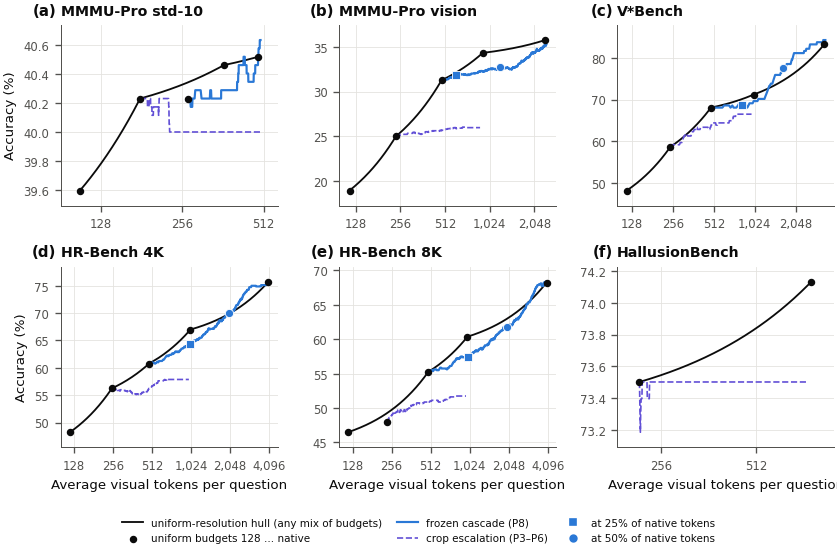

⏱ P8.F1 frozen policy vs uniform resolution, every benchmark | wall 4.93 s | CPU 5.00 s (1.01 cores, sys 66.2%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB
figure -> /content/rave_work/figures/fig_p8_2_lobo.pdf


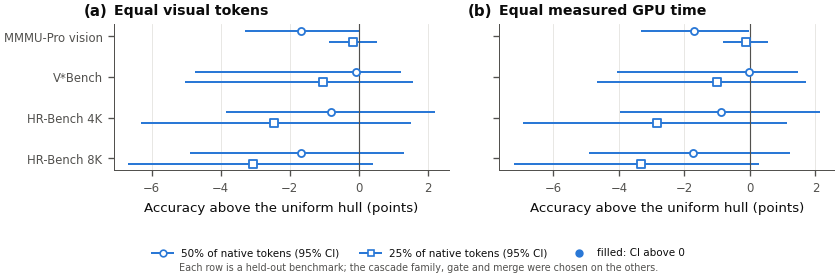

⏱ P8.F2 leave-one-benchmark-out | wall 1.20 s | CPU 1.22 s (1.02 cores, sys 59.0%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB
figure -> /content/rave_work/figures/fig_p8_3_uplift.pdf


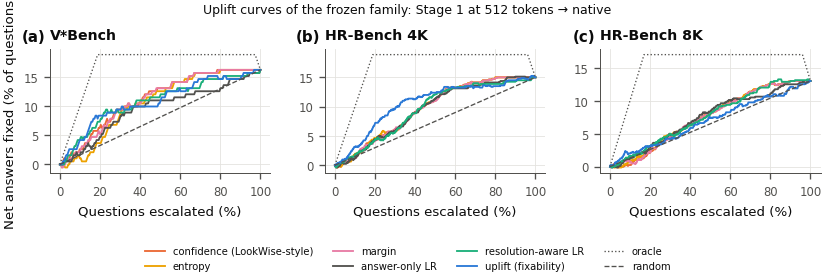

⏱ P8.F3 uplift curves | wall 1.47 s | CPU 1.47 s (1.0 cores, sys 56.2%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB
figure -> /content/rave_work/figures/fig_p8_4_three_stage.pdf


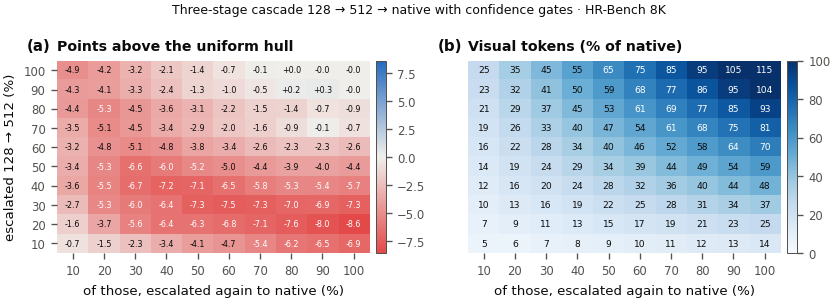

⏱ P8.F4 three-stage heat map | wall 2.27 s | CPU 2.30 s (1.01 cores, sys 54.5%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB
⏱ cell 19: POL_C = {"conf": COLORS["LookWise_conf"], "entropy": COLORS[ | wall 9.94 s | CPU 10.04 s (1.01 cores, sys 60.8%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB


In [21]:
POL_C = {"conf": COLORS["LookWise_conf"], "entropy": COLORS["A1_entropy"], "margin": "#e87ba4", "lr_ans": INK2,
         "lr_res": COLORS["LazyMCoT_GBDT"], "uplift": COLORS["RAVE_risk"]}
POL_N = {"conf": "confidence (LookWise-style)", "entropy": "entropy", "margin": "margin", "lr_ans": "answer-only LR",
         "lr_res": "resolution-aware LR", "uplift": "uplift (fixability)"}
P0 = FROZEN["policy"]

with Phase("P8.F1 frozen policy vs uniform resolution, every benchmark", budget_min=3):
    keys = [k for k in D8 if k != "mmmu_std_4b"]
    nc = 3; nr = int(np.ceil(len(keys) / nc))
    fig, axs = plt.subplots(nr, nc, figsize=(COL2, 2.1 * nr + 0.6), squeeze=False)
    for j, k in enumerate(keys):
        ax = axs[j // nc, j % nc]; R_ = D8[k]; EV = R_["EV"]
        xs = [f.vis_tokens.mean() for f in R_["b0al"]]; ys = [100 * f.correct.mean() for f in R_["b0al"]]
        hx, hy = upper_hull(xs, ys)
        xd = np.geomspace(hx[0], hx[-1], 200)             # the hull is linear in tokens: densify for the log axis
        ax.plot(xd, hull_value(xd, hx, hy), color=INK, lw=1.1, zorder=3, label="uniform-resolution hull (any mix of budgets)")
        ax.scatter(xs, ys, color=INK, s=12, zorder=6, label="uniform budgets 128 … native")
        s1, kind = P0["s1"], P0["target"]
        if s1 in EV.RES and kind in EV.RES[s1]:
            sc = gate_score(P0["gate"], R_["frames"][s1], s1)
            cv = cascade_curve(EV, s1, kind, sc, P0["merge"])
            m_ = cv["tok"] <= 1.02 * max(xs)
            ax.plot(cv["tok"][m_], 100 * cv["acc"][m_], color=COLORS["RAVE_risk"], lw=1.3, zorder=4,
                    label="frozen cascade (P8)")
            for phi, mk in ((0.25, "s"), (0.5, "o")):
                r_ = apply_frozen_policy(R_, P0, phi, n_boot=0)
                if r_:
                    ax.scatter([r_["tok_frac"] * R_["native_tok"]], [r_["acc"]], color=COLORS["RAVE_risk"], marker=mk, s=24,
                               zorder=5, edgecolor="white", linewidth=0.5)
        if B in EV.RES and "joint_top1" in EV.RES[B]:
            cv2 = cascade_curve(EV, B, "joint_top1", 1 - R_["frames"][B].maxp.values, "M2")
            m_ = cv2["tok"] <= 1.02 * max(xs)
            ax.plot(cv2["tok"][m_], 100 * cv2["acc"][m_], color=COLORS["RAVE_VoI"], lw=1.0, ls="--", zorder=3,
                    label="crop escalation (P3–P6)")
        token_axis(ax, min(xs), max(xs)); ax.margins(y=0.1)
        ax.set_title(LABEL[k].replace(" · 8B", "")); panel(ax, "abcdefgh"[j])
        if j % nc == 0:
            ax.set_ylabel("Accuracy (%)")
        if j // nc == nr - 1:
            ax.set_xlabel("Average visual tokens per question")
    for j in range(len(keys), nr * nc):
        axs[j // nc, j % nc].axis("off")
    h_, l_ = axs[0, 0].get_legend_handles_labels()
    h_ += [Line2D([], [], color=COLORS["RAVE_risk"], marker="s", ls=""), Line2D([], [], color=COLORS["RAVE_risk"], marker="o", ls="")]
    l_ += ["at 25% of native tokens", "at 50% of native tokens"]
    fig.tight_layout(rect=(0, 0.1, 1, 1), h_pad=1.0)
    fig.legend(h_, l_, loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.095), fontsize=6.2, columnspacing=1.4)
    save_fig(fig, "fig_p8_1_frozen_cascade")

with Phase("P8.F2 leave-one-benchmark-out", budget_min=2):
    fig, axs = plt.subplots(1, 2, figsize=(COL2, 0.32 * len(PERC) + 1.1), sharey=True)
    for ax, (col, lo, hi, ttl) in zip(axs, (("gap_tok", "gap_tok_lo", "gap_tok_hi", "Equal visual tokens"),
                                             ("gap_comp", "gap_comp_lo", "gap_comp_hi", "Equal measured GPU time"))):
        ys = np.arange(len(PERC))[::-1]
        for phi, off, mk in ((0.5, 0.13, "o"), (0.25, -0.13, "s")):
            sub = LOBO[LOBO.phi == phi].set_index("held_out")
            for yv, k in zip(ys, PERC):
                if k in sub.index:
                    r_ = sub.loc[k]; sig = r_[lo] > 0
                    ax.plot([r_[lo], r_[hi]], [yv + off] * 2, color=COLORS["RAVE_risk"], lw=1.2)
                    ax.scatter([r_[col]], [yv + off], marker=mk, s=18, zorder=3, color=COLORS["RAVE_risk"] if sig else "white",
                               edgecolor=COLORS["RAVE_risk"], linewidth=1.1,
                               label=f"{int(phi * 100)}% of native tokens" if yv == ys[0] else None)
        ax.axvline(0, color=INK2, lw=0.7); ax.grid(axis="y", visible=False)
        ax.set_xlabel("Accuracy above the uniform hull (points)"); ax.set_title(ttl)
    axs[0].set_yticks(np.arange(len(PERC))[::-1], [LABEL[k].replace(" · 8B", "") for k in PERC])
    panel(axs[0], "a"); panel(axs[1], "b")
    h_ = [Line2D([], [], color=COLORS["RAVE_risk"], marker="o", ls="-", lw=1.2, markerfacecolor="white"),
          Line2D([], [], color=COLORS["RAVE_risk"], marker="s", ls="-", lw=1.2, markerfacecolor="white"),
          Line2D([], [], color=COLORS["RAVE_risk"], marker="o", ls="", markerfacecolor=COLORS["RAVE_risk"])]
    fig.tight_layout(rect=(0, 0.15, 1, 1), w_pad=1.5)
    fig.legend(h_, ["50% of native tokens (95% CI)", "25% of native tokens (95% CI)", "filled: CI above 0"],
               loc="upper center", ncol=3, bbox_to_anchor=(0.5, 0.115), fontsize=6.2)
    fig.text(0.5, 0.005, "Each row is a held-out benchmark; the cascade family, gate and merge were chosen on the others.",
             ha="center", fontsize=5.8, color=INK2)
    save_fig(fig, "fig_p8_2_lobo")

with Phase("P8.F3 uplift curves", budget_min=2):
    s1f, kf = P0["s1"], P0["target"]
    show = [k for k in ("vstar_8b", "hr4k_8b", "hr8k_8b", "mmmu_vision_8b") if k in D8 and kf in D8[k]["EV"].MERGE.get(s1f, {})][:3]
    if show:
        fig, axs = plt.subplots(1, len(show), figsize=(COL2, 2.3), squeeze=False)
        for j, k in enumerate(show):
            ax = axs[0, j]; EV = D8[k]["EV"]
            G = gate_scores_in(D8[k], s1f, kf, P0["merge"])
            gain = EV.MERGE[s1f][kf][P0["merge"]] - EV.RES[s1f]["global"]["correct"]
            for gname in PLAN8["gates"]:
                q_, cg, co, rnd = qini(gain, G[gname])
                x = np.linspace(0, 100, len(cg))
                ax.plot(x, 100 * cg / EV.N, color=POL_C[gname], lw=1.1, label=POL_N[gname] if j == 0 else None)
            ax.plot(x, 100 * co / EV.N, color=INK2, lw=0.8, ls=":", label="oracle" if j == 0 else None)
            ax.plot(x, 100 * rnd / EV.N, color=INK2, lw=0.8, ls="--", label="random" if j == 0 else None)
            ax.set_title(LABEL[k].replace(" · 8B", "")); ax.set_xlabel("Questions escalated (%)")
            if j == 0:
                ax.set_ylabel("Net answers fixed (% of questions)")
            panel(ax, "abc"[j])
        h_, l_ = axs[0, 0].get_legend_handles_labels()
        fig.tight_layout(rect=(0, 0.15, 1, 0.95))
        fig.suptitle(f"Uplift curves of the frozen family: Stage 1 at {s1f} tokens → {kf.replace('res_', '')}", fontsize=7.5)
        fig.legend(h_, l_, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 0.13), fontsize=6.0)
        save_fig(fig, "fig_p8_3_uplift")

with Phase("P8.F4 three-stage heat map", budget_min=2):
    k3 = next((k for k in ("hr8k_8b", "hr4k_8b", "vstar_8b") if k in PERC and len(TS[TS.exp == k])), None)
    if k3:
        M_ = TS[(TS.exp == k3) & (TS.gate == "conf")].pivot_table(index="r1", columns="r2", values="gap_tok")
        F_ = TS[(TS.exp == k3) & (TS.gate == "conf")].pivot_table(index="r1", columns="r2", values="tok_frac")
        fig, axs = plt.subplots(1, 2, figsize=(COL2, 2.6))
        im = plot_heat(axs[0], M_.values[::-1], [f"{100 * v:.0f}" for v in M_.index[::-1]], [f"{100 * v:.0f}" for v in M_.columns],
                       fmt="{:+.1f}")
        for t_ in axs[0].texts:
            t_.set_fontsize(4.8)
        axs[0].set_xlabel("of those, escalated again to native (%)"); axs[0].set_ylabel("escalated 128 → 512 (%)")
        axs[0].set_title("Points above the uniform hull"); fig.colorbar(im, ax=axs[0], fraction=0.04, pad=0.02)
        im2 = axs[1].imshow(100 * F_.values[::-1], cmap="Blues", vmin=0, vmax=100, aspect="auto")
        for i in range(F_.shape[0]):
            for j in range(F_.shape[1]):
                v = 100 * F_.values[::-1][i, j]
                axs[1].text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=5.5, color="white" if v > 60 else INK)
        axs[1].set_xticks(range(F_.shape[1]), [f"{100 * v:.0f}" for v in F_.columns]); axs[1].set_yticks([]); axs[1].grid(False)
        for sp in axs[1].spines.values():
            sp.set_visible(False)
        axs[1].set_title("Visual tokens (% of native)"); axs[1].set_xlabel("of those, escalated again to native (%)")
        fig.colorbar(im2, ax=axs[1], fraction=0.04, pad=0.02)
        panel(axs[0], "a"); panel(axs[1], "b")
        fig.tight_layout(rect=(0, 0, 1, 0.93), w_pad=1.5)
        fig.suptitle(f"Three-stage cascade 128 → 512 → native with confidence gates · {LABEL[k3].replace(' · 8B', '')}",
                     fontsize=7.5, y=0.99)
        save_fig(fig, "fig_p8_4_three_stage")

## Summary — save everything to Drive

In [22]:
summary = dict(plan_sha256=plan_hash, frozen_policy_sha256=FROZEN["sha256"], frozen=FROZEN["policy"], verdict=V8,
               lobo=LOBO.drop(columns=[c for c in LOBO.columns if c in ("c", "esc")]).to_dict("records"),
               tables=sorted(p.name for p in P8.glob("*.tex")), figures=sorted(p.name for p in FIG_DIR.glob("fig_p8_*.pdf")))
(DIRS["logs"] / "results_summary_p8.json").write_text(json.dumps(summary, indent=2, default=float))
time_report("P8")
sync_to_drive(quiet=False)
save_notebook_copy("RAVE_v4_P8_policy_search")

[P8] 19 cells | wall 5.6 min | CPU 0.8 CPU-min (0.1 cores avg) | GPU busy 0.00 min (phases) / 0.00 min (cells, NVML) | GPU energy 0.0 kJ
Drive sync: 0 file(s) -> /content/drive/MyDrive/Koushik 2/rave_work
notebook with outputs -> /content/drive/MyDrive/Koushik 2/notebooks/RAVE_v4_P8_policy_search_executed_20261021_1419.ipynb
⏱ cell 20: summary = dict(plan_sha256=plan_hash, frozen_policy_sha256=F | wall 1.11 s | CPU 0.10 s (0.09 cores, sys 17.6%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB
